# **INPUT DATA:**

In [48]:
import pandas as pd
from pathlib import Path

# Folder holding the raw data files (relative to this notebook, in 'Jupyter Notebooks/')
DATA_DIR = Path('../DATA')


def data_file(name):
    """Return DATA_DIR/name, or its zipped copy (name.zip) if the CSV is not present."""
    path = DATA_DIR / name
    return path if path.exists() else DATA_DIR / (name + '.zip')

# Define path to the occupancy sensor dataset
file_path = data_file('5occupancySensor_MayToDec2024_9MRows.csv')

# Load the occupancy dataset into a pandas DataFrame
# Set low_memory=False to suppress mixed-type warnings and skip bad lines on parsing failure
df = pd.read_csv(file_path, on_bad_lines='skip', low_memory=False)

Let's look at the first few rows of the DataFrame to understand its structure.

In [49]:
# Render the first 5 records of the loaded occupancy dataset to inspect headers and values
display(df.head())

,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-24 00:36:52+11,2023-11-24 00:36:52+11,NotOccupied
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,CurrentlyOccupied
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,NotOccupied
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,RecentlyOccupied
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,CurrentlyOccupied


Now, let's get a summary of the DataFrame, including column names, non-null counts, and data types.

In [50]:
# Print comprehensive metadata summary of the occupancy dataset
# This details the index, column labels, non-null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column                     Non-Null Count    Dtype 
---  ------                     --------------    ----- 
 0   id                         1048575 non-null  int64 
 1   deviceid                   1048575 non-null  object
 2   floorspaceid               1048575 non-null  object
 3   occupancystatus            1048575 non-null  object
 4   headcount                  1048575 non-null  int64 
 5   collecteddate              1048575 non-null  object
 6   occupancystatuschangedate  1048575 non-null  object
 7   previousoccupancystatus    1048575 non-null  object
dtypes: int64(2), object(6)
memory usage: 64.0+ MB


First, let's convert the `collecteddate` column to a datetime format so we can perform time-based analysis.

In [51]:
# Convert the timestamp column 'collecteddate' to standardized datetime format
# 'mixed' format is used to handle parsing variety, and invalid times are coerced to NaT
df['collecteddate'] = pd.to_datetime(df['collecteddate'], format='mixed', utc=True, errors='coerce')

# Print the total number of dates that could not be successfully parsed
print(f"Number of unparseable dates: {df['collecteddate'].isna().sum()}")
display(df[['collecteddate']].head())


Number of unparseable dates: 0


,collecteddate
0,2023-11-23 13:36:52+00:00
1,2023-11-23 13:37:32+00:00
2,2023-11-23 13:37:32+00:00
3,2023-11-23 13:37:52+00:00
4,2023-11-23 13:37:52+00:00


### Select the Modelling Room

The occupancy data contains five rooms (`floorspaceid`) reported by a single device. Only environmental sensor 869 overlaps the occupancy data in time, and after removing time-of-day effects its CO₂ tracks room **941f0352** most closely (r = 0.32, versus 0.25 or less for the other rooms). The model is therefore built on this one room.


In [52]:
# Occupancy room used for modelling
ROOM_ID = '941f0352-bb69-47d0-a9c5-ac29eb4f7319'

print(f"Occupancy rows (all rooms): {len(df):,}")
df = df[df['floorspaceid'] == ROOM_ID].copy()
df['headcount'] = pd.to_numeric(df['headcount'], errors='coerce')
df = df.dropna(subset=['collecteddate', 'headcount']).sort_values('collecteddate').reset_index(drop=True)

print(f"Occupancy rows for room {ROOM_ID[:8]}: {len(df):,}")
print(f"Time span: {df['collecteddate'].min()} to {df['collecteddate'].max()}")


Occupancy rows (all rooms): 1,048,575
Occupancy rows for room 941f0352: 289,206
Time span: 2023-11-23 13:36:52+00:00 to 2024-05-06 01:37:50+00:00


In [53]:
# Load the sensor-room mapping registry
excel_path = DATA_DIR / 'Sensor ID and Locations.xlsx'
sensor_locations_df = pd.read_excel(excel_path)

print("Sensor Locations Dataset Overview:")
sensor_locations_df.info()
display(sensor_locations_df.head(10))

# The registry lists environmental sensors only (no occupancy rooms), so it cannot be used
# to join sensors to occupancy rooms directly. It does locate the modelling sensor (869):
print("Registry entry for environmental sensor 6012002000869:")
display(sensor_locations_df[sensor_locations_df['ID'].astype(str) == '6012002000869'])


Sensor Locations Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Building        78 non-null     int64 
 1   Floor/Room      78 non-null     object
 2   Area            78 non-null     object
 3   Physical Label  78 non-null     object
 4   Sensor          78 non-null     object
 5   ID              78 non-null     int64 
dtypes: int64(2), object(4)
memory usage: 3.8+ KB


,Building,Floor/Room,Area,Physical Label,Sensor,ID
0,60,1-PS01,Corridor,ES1104,Env,6012003000486
1,69,1-PS02,Breakout,ES2113,Env,6012003000882
2,60,1.40,Board Room,ES1102,Env,6012003000462
3,60,1.41,Open Office,ES1110,Env,6012003000424
4,60,1.41A,Focus Room 1,ES1101,Env,6012003000448
5,60,1.42,Startup Workshop,ES1103,Env,6012003000479
6,60,1.43,Startup,ES1105,Env,6012003000493
7,60,1.45,Meeting Room,ES1106,Env,6012003000509
8,60,1.47,Corridor,ES1107,Env,6012003000516
9,60,1.49,Workshop,ES1108,Env,6012003000530


Registry entry for environmental sensor 6012002000869:


,Building,Floor/Room,Area,Physical Label,Sensor,ID
60,60,G.38,Compactus_upper,EMS107,Env,6012002000869


# **Load Env. Data**

In [54]:
import json
import numpy as np

# Environmental sensor used for modelling.
# Sensor 869 is the only env sensor whose readings overlap the occupancy data in time:
#   - sensors 227, 241 and 777 repeat a single frozen reading (no usable data)
#   - sensor 326 only has readings from late 2025 onwards
ENV_SENSOR_ID = 6012002000869
EXCLUDED_VARIABLES = ['Battery']  # sensor battery voltage, not an environmental measurement

env_file_path = data_file('5EnvSensor_MayToDec2024_180kRows.csv')

# Load only the columns we need, then keep sensor 869
env_df = pd.read_csv(
    env_file_path,
    usecols=['id', 'sensorid', 'jsondata', 'createdate'],
    on_bad_lines='skip',
    engine='python'
)
env_df = env_df[env_df['sensorid'] == ENV_SENSOR_ID]

# 'createdate' is when a record was uploaded, which can be months after it was measured.
# Each variable inside 'jsondata' carries its own measurement timestamp, so we use that instead.
records = []
for raw in env_df['jsondata']:
    try:
        variables = json.loads(raw)
    except (TypeError, json.JSONDecodeError):
        continue
    for var in variables:
        name = var.get('variable', {}).get('name')
        values = var.get('values') or []
        if name is None or name in EXCLUDED_VARIABLES or not values:
            continue
        records.append((values[0].get('time'), name, values[0].get('value')))

long_env = pd.DataFrame(records, columns=['unix_time', 'variable', 'value'])
long_env['value'] = pd.to_numeric(long_env['value'], errors='coerce')
long_env['measuredate'] = pd.to_datetime(long_env['unix_time'], unit='s', utc=True, errors='coerce')

# Each measurement is uploaded more than once, so keep one value per variable per timestamp
# and reshape to one row per measurement time with one column per variable
cleaned_env_df = (
    long_env.dropna(subset=['measuredate'])
    .pivot_table(index='measuredate', columns='variable', values='value', aggfunc='first')
    .reset_index()
    .sort_values('measuredate')
    .reset_index(drop=True)
)
cleaned_env_df.columns.name = None
cleaned_env_df.insert(0, 'sensorid', ENV_SENSOR_ID)

# All environmental variables (everything except Battery) become model features
FEATURES = [c for c in cleaned_env_df.columns if c not in ('sensorid', 'measuredate')]

print(f"Sensor {ENV_SENSOR_ID}: {len(cleaned_env_df):,} unique measurements")
print(f"Measured from {cleaned_env_df['measuredate'].min()} to {cleaned_env_df['measuredate'].max()}")
print(f"Features ({len(FEATURES)}): {FEATURES}")


Sensor 6012002000869: 13,800 unique measurements
Measured from 2024-02-29 06:04:56+00:00 to 2024-06-13 17:45:44+00:00
Features (10): ['Carbon dioxide', 'Formaldehyde', 'Humidity', 'Light Volatile Organic Compounds', 'Particulate matter 1', 'Particulate matter 10', 'Particulate matter 2.5', 'Particulate matter 4', 'Pressure', 'Temperature']


In [55]:
# Summary of the environmental measurements from sensor 869
print("Environmental sensor data (one row per measurement time):")
cleaned_env_df.info()
display(cleaned_env_df[FEATURES].describe().T)
display(cleaned_env_df.head(5))


Environmental sensor data (one row per measurement time):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13800 entries, 0 to 13799
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype              
---  ------                            --------------  -----              
 0   sensorid                          13800 non-null  int64              
 1   measuredate                       13800 non-null  datetime64[ns, UTC]
 2   Carbon dioxide                    13800 non-null  float64            
 3   Formaldehyde                      13800 non-null  float64            
 4   Humidity                          13800 non-null  float64            
 5   Light Volatile Organic Compounds  13800 non-null  float64            
 6   Particulate matter 1              13800 non-null  float64            
 7   Particulate matter 10             13800 non-null  float64            
 8   Particulate matter 2.5            13800 non-null  float64            
 9   Par

,count,mean,std,min,25%,50%,75%,max
Carbon dioxide,13800.0,473.985217,39.403080,403.0,444.0,463.0,494.0,646.0
Formaldehyde,13800.0,35.118768,11.458209,17.0,25.0,35.0,46.0,55.0
Humidity,13800.0,45.033841,7.394367,26.0,40.0,45.0,49.0,75.0
Light Volatile Organic Compounds,13800.0,10.458841,35.391380,0.0,0.0,0.0,1.0,729.0
Particulate matter 1,13800.0,3.516812,6.861366,0.0,1.0,1.0,3.0,73.0
Particulate matter 10,13800.0,5.725362,8.237810,0.0,2.0,3.0,6.0,83.0
Particulate matter 2.5,13800.0,4.708623,7.665725,0.0,1.0,3.0,4.0,79.0
Particulate matter 4,13800.0,5.557754,8.132900,0.0,2.0,3.0,6.0,81.0
Pressure,13800.0,1017.825797,5.661114,1002.0,1014.0,1019.0,1022.0,1028.0
Temperature,13800.0,23.089514,1.163156,19.0,22.5,23.3,23.8,28.5


,sensorid,measuredate,Carbon dioxide,Formaldehyde,Humidity,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 10,Particulate matter 2.5,Particulate matter 4,Pressure,Temperature
0,6012002000869,2024-02-29 06:04:56+00:00,465.0,17.0,56.0,0.0,2.0,2.0,2.0,2.0,1010.0,24.3
1,6012002000869,2024-02-29 06:14:57+00:00,445.0,17.0,56.0,0.0,2.0,5.0,4.0,5.0,1010.0,24.0
2,6012002000869,2024-02-29 06:34:57+00:00,471.0,17.0,56.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8
3,6012002000869,2024-02-29 06:44:57+00:00,457.0,17.0,56.0,0.0,1.0,3.0,2.0,2.0,1010.0,23.8
4,6012002000869,2024-02-29 06:54:57+00:00,455.0,17.0,57.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8


# Task
Check the time spacing of the occupancy and environmental datasets, then align them: pair each environmental reading from sensor 869 with the time-weighted average headcount of room 941f0352 over the preceding 10 minutes.


## Analyze Time Series Spacing

### Subtask:
Calculate the time differences between consecutive timestamps in both datasets to check for even or uneven spacing.


**Reasoning**:
Sort both datasets by time and summarise the gaps between consecutive readings, to choose a common time interval that suits both sampling rates.


In [56]:
# 1. Sort both datasets by their timestamp columns
# (cleaned_env_df already uses the true measurement time, 'measuredate')
df = df.sort_values(by='collecteddate')
cleaned_env_df = cleaned_env_df.sort_values(by='measuredate')

# 2. Calculate time differences between consecutive timestamps
df['time_diff'] = df['collecteddate'].diff()
cleaned_env_df['time_diff'] = cleaned_env_df['measuredate'].diff()

# 3. Compute and print summary statistics for the time differences
print("=== Occupancy Dataset (df) Time Differences Summary ===")
print(df['time_diff'].describe())

print("\n=== Environmental Dataset (cleaned_env_df) Time Differences Summary ===")
print(cleaned_env_df['time_diff'].describe())


=== Occupancy Dataset (df) Time Differences Summary ===
count                       289205
mean     0 days 00:00:49.144579104
std      0 days 00:43:16.659141985
min                0 days 00:00:02
25%                0 days 00:00:02
50%                0 days 00:00:04
75%                0 days 00:00:20
max               15 days 14:56:22
Name: time_diff, dtype: object

=== Environmental Dataset (cleaned_env_df) Time Differences Summary ===
count                        13799
mean     0 days 00:11:00.486122182
std      0 days 00:03:00.795167723
min                0 days 00:09:34
25%                0 days 00:10:00
50%                0 days 00:10:00
75%                0 days 00:10:00
max                0 days 00:29:59
Name: time_diff, dtype: object


## Explain the Alignment Method

### Subtask:
Explain how the occupancy data is condensed to match the timing of the environmental readings.


### Aligning Occupancy to the Environmental Readings

The two datasets are sampled very differently:

* **Environmental sensor 869** records every variable at the same moment, on a regular **10-minute** interval (occasionally 20 minutes when a reading is missed). These readings are used **as they are**, with no averaging or interpolation.
* **Occupancy (room 941f0352)** is recorded every few seconds at irregular intervals, with occasional gaps of hours to days.

To pair them, each environmental reading at time *t* is matched with the **time-weighted average headcount over the preceding 10 minutes**, [*t* − 10 min, *t*].

**Why a step (zero-order hold) average rather than the trapezoidal rule:** a headcount is a count of people that stays constant until someone enters or leaves, so between two readings the true value is the earlier reading, not a straight line between them. The time-weighted average is therefore:

$$\bar{H} = \frac{1}{T_{valid}} \sum_i h_i \, \Delta t_i$$

where each reading *hᵢ* is weighted by how long it was held (Δ*tᵢ*) within the window.

**Handling gaps:** a reading is not carried forward across a gap longer than 10 minutes. A window is only used if valid occupancy data covers at least 80% of it, and the average is divided by that covered time, *T_valid*.


## Align Occupancy to Each Environmental Reading

### Subtask:
For every 10-minute environmental reading, compute the time-weighted average headcount over the preceding 10 minutes.


**Reasoning**:
The headcount is treated as a step function (each value holds until the next reading). Its cumulative area and cumulative valid time are calculated once, so the average over any window is the difference in area divided by the difference in valid time. This is fast even for hundreds of thousands of occupancy readings.


In [57]:
import numpy as np

WINDOW = pd.Timedelta('10min')   # matches sensor 869's 10-minute reporting interval
MAX_GAP = pd.Timedelta('10min')  # don't carry a headcount across longer gaps in the occupancy data
MIN_COVERAGE = 0.8               # require valid occupancy data for at least 80% of each window

def to_seconds(times):
    """Convert a datetime Series to seconds since 1970 as a float array."""
    return (times - pd.Timestamp('1970-01-01', tz='UTC')).dt.total_seconds().to_numpy()

# 1. Occupancy as a step function: each headcount holds until the next reading
occ = df.groupby('collecteddate', as_index=False)['headcount'].mean()  # merge simultaneous readings
t = to_seconds(occ['collecteddate'])
h = occ['headcount'].to_numpy(dtype=float)

seg_len = np.diff(t)                                  # how long each reading is held
seg_valid = seg_len <= MAX_GAP.total_seconds()        # ignore segments that span a long gap

# Cumulative area under the step function, and cumulative valid time, at each reading
cum_area = np.concatenate([[0.0], np.cumsum(np.where(seg_valid, h[:-1] * seg_len, 0.0))])
cum_time = np.concatenate([[0.0], np.cumsum(np.where(seg_valid, seg_len, 0.0))])

def cumulative_at(x):
    """Area and valid time accumulated from the first occupancy reading up to time(s) x."""
    k = np.clip(np.searchsorted(t, x, side='right') - 1, 0, len(t) - 2)  # segment containing x
    partial = np.clip(x - t[k], 0, seg_len[k])
    partial = np.where(seg_valid[k], partial, 0.0)
    area = cum_area[k] + h[k] * partial
    valid_time = cum_time[k] + partial
    # Before the first reading nothing has accumulated; after the last, everything has
    area = np.where(x < t[0], 0.0, np.where(x > t[-1], cum_area[-1], area))
    valid_time = np.where(x < t[0], 0.0, np.where(x > t[-1], cum_time[-1], valid_time))
    return area, valid_time

# 2. Time-weighted average headcount over the 10 minutes before each environmental reading
window_end = to_seconds(cleaned_env_df['measuredate'])
window_start = window_end - WINDOW.total_seconds()

area_end, time_end = cumulative_at(window_end)
area_start, time_start = cumulative_at(window_start)
covered = time_end - time_start

enough_data = covered >= MIN_COVERAGE * WINDOW.total_seconds()
avg_headcount = np.full(len(window_end), np.nan)
avg_headcount[enough_data] = (area_end - area_start)[enough_data] / covered[enough_data]

# 3. Outputs used by the rest of the notebook (one row per environmental reading)
binned_occ_df = pd.DataFrame({
    'time': cleaned_env_df['measuredate'].to_numpy(),
    'avg_headcount': avg_headcount
}).dropna()

binned_env_df = (
    cleaned_env_df.rename(columns={'measuredate': 'time'})[['time'] + FEATURES]
    .reset_index(drop=True)
)

print(f"Environmental readings: {len(binned_env_df):,}")
print(f"Readings with enough occupancy data for a 10-minute average: {len(binned_occ_df):,}")

print("\n=== 10-Minute Occupancy Averages ===")
display(binned_occ_df.head())

print("\n=== Environmental Readings ===")
display(binned_env_df.head())


Environmental readings: 13,800
Readings with enough occupancy data for a 10-minute average: 4,009

=== 10-Minute Occupancy Averages ===


,time,avg_headcount
0,2024-02-29 06:04:56+00:00,1.276667
1,2024-02-29 06:14:57+00:00,1.153333
2,2024-02-29 06:34:57+00:00,1.415000
3,2024-02-29 06:44:57+00:00,2.045000
4,2024-02-29 06:54:57+00:00,1.940000



=== Environmental Readings ===


,time,Carbon dioxide,Formaldehyde,Humidity,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 10,Particulate matter 2.5,Particulate matter 4,Pressure,Temperature
0,2024-02-29 06:04:56+00:00,465.0,17.0,56.0,0.0,2.0,2.0,2.0,2.0,1010.0,24.3
1,2024-02-29 06:14:57+00:00,445.0,17.0,56.0,0.0,2.0,5.0,4.0,5.0,1010.0,24.0
2,2024-02-29 06:34:57+00:00,471.0,17.0,56.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8
3,2024-02-29 06:44:57+00:00,457.0,17.0,56.0,0.0,1.0,3.0,2.0,2.0,1010.0,23.8
4,2024-02-29 06:54:57+00:00,455.0,17.0,57.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8


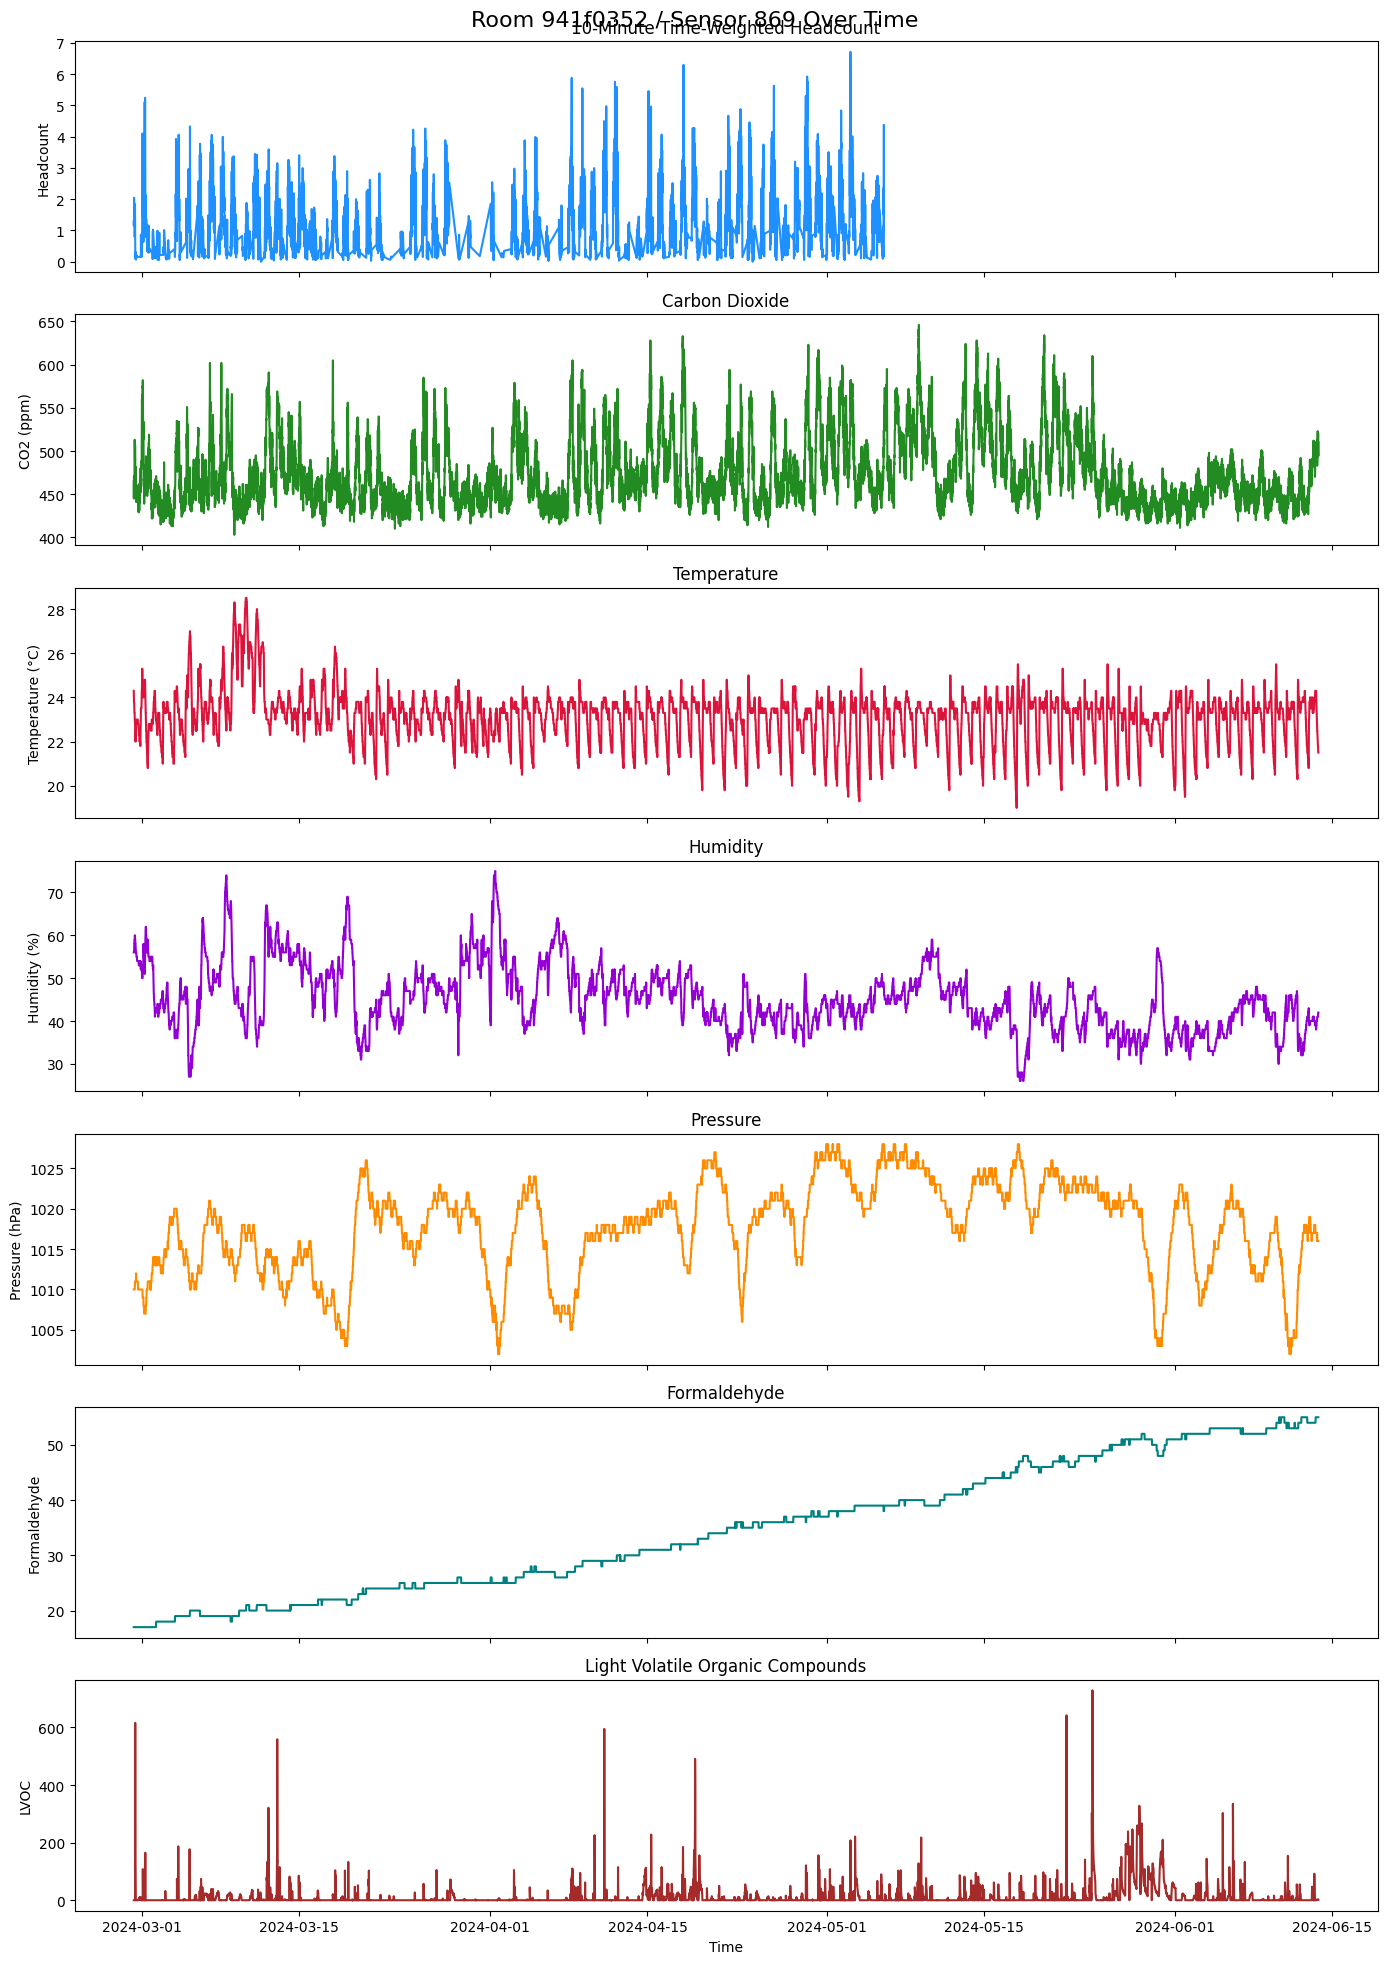

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Single room and single sensor, so no aggregation across devices is needed
occ_agg = binned_occ_df.copy()
env_agg = binned_env_df.copy()

# Set up the figure and subplots
fig, axes = plt.subplots(7, 1, figsize=(14, 20), sharex=True)
fig.suptitle('Room 941f0352 / Sensor 869 Over Time', fontsize=16)

# 1. Headcount
sns.lineplot(data=occ_agg, x='time', y='avg_headcount', ax=axes[0], color='dodgerblue')
axes[0].set_ylabel('Headcount')
axes[0].set_title('10-Minute Time-Weighted Headcount')

# 2. Carbon Dioxide (CO2)
sns.lineplot(data=env_agg, x='time', y='Carbon dioxide', ax=axes[1], color='forestgreen')
axes[1].set_ylabel('CO2 (ppm)')
axes[1].set_title('Carbon Dioxide')

# 3. Temperature
sns.lineplot(data=env_agg, x='time', y='Temperature', ax=axes[2], color='crimson')
axes[2].set_ylabel('Temperature (°C)')
axes[2].set_title('Temperature')

# 4. Humidity
sns.lineplot(data=env_agg, x='time', y='Humidity', ax=axes[3], color='darkviolet')
axes[3].set_ylabel('Humidity (%)')
axes[3].set_title('Humidity')

# 5. Pressure
sns.lineplot(data=env_agg, x='time', y='Pressure', ax=axes[4], color='darkorange')
axes[4].set_ylabel('Pressure (hPa)')
axes[4].set_title('Pressure')

# 6. Formaldehyde
sns.lineplot(data=env_agg, x='time', y='Formaldehyde', ax=axes[5], color='teal')
axes[5].set_ylabel('Formaldehyde')
axes[5].set_title('Formaldehyde')

# 7. LVOC
sns.lineplot(data=env_agg, x='time', y='Light Volatile Organic Compounds', ax=axes[6], color='brown')
axes[6].set_ylabel('LVOC')
axes[6].set_title('Light Volatile Organic Compounds')
axes[6].set_xlabel('Time')

plt.tight_layout()
plt.show()

### Data Verification: Raw Headcount Measurements

This plot shows the raw, unaggregated headcount events for room 941f0352. Occupancy is highly discrete (sharp steps as people enter and leave) and contains long gaps where no data was recorded. This is why the headcount is condensed into 10-minute time-weighted averages before modelling, and why windows without enough occupancy data are excluded.


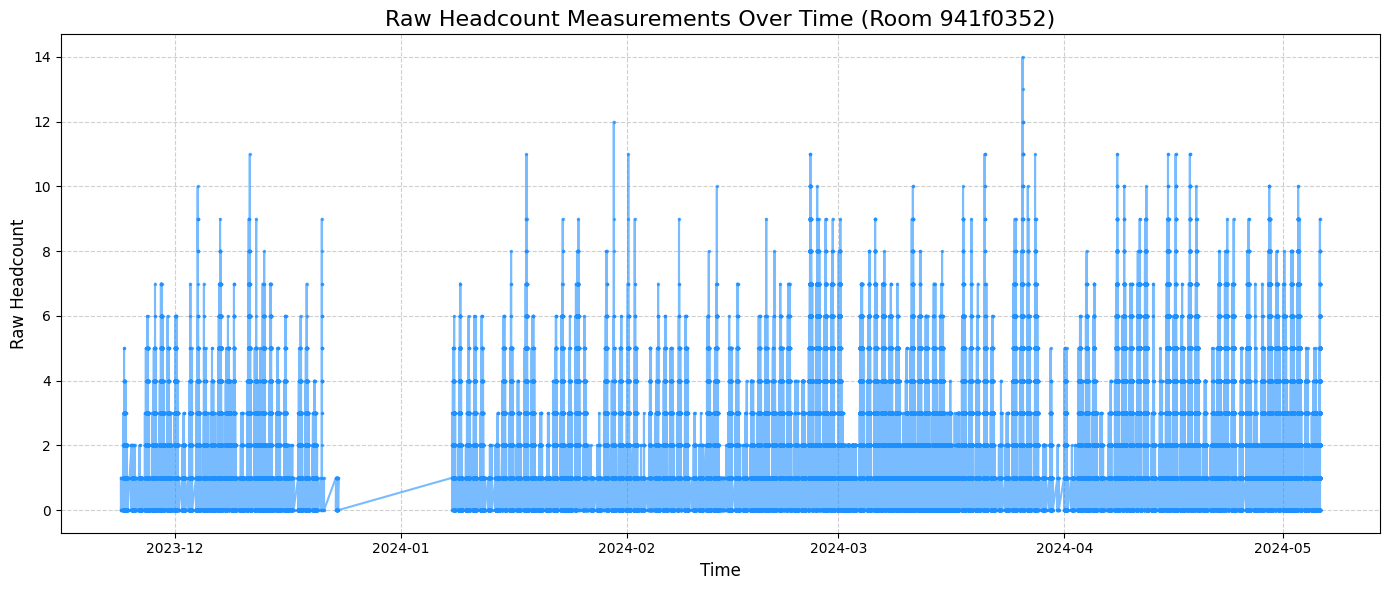

In [59]:
import matplotlib.pyplot as plt

# Prepare the raw data by dropping missing values and sorting by time
raw_plot_df = df.dropna(subset=['collecteddate', 'headcount']).sort_values('collecteddate')

# Create a plot of the raw headcount data over time
plt.figure(figsize=(14, 6))
plt.plot(raw_plot_df['collecteddate'], raw_plot_df['headcount'],
         marker='.', linestyle='-', markersize=3, alpha=0.6, color='dodgerblue')

plt.title('Raw Headcount Measurements Over Time (Room 941f0352)', fontsize=16)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Raw Headcount', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Dataset Merging and Overlap Analysis

To prepare for modelling, we merge the 10-minute occupancy averages with the environmental readings on their shared timestamps. We then count how many readings have both a headcount and all environmental variables (used for training and validation), and how many have only one or the other.


In [60]:
import pandas as pd

# Merge the occupancy and environmental aggregates on the 'time' column
# Using an outer join to keep all timestamps from both datasets
merged_df = pd.merge(occ_agg, env_agg, on='time', how='outer').sort_values('time').reset_index(drop=True)

# Calculate overlapping points (all variables exist)
train_data = merged_df.dropna(subset=['avg_headcount'] + FEATURES)
num_train_points = len(train_data)

# Calculate points where ONLY headcount exists (environmental data is missing)
only_headcount_data = merged_df[merged_df['avg_headcount'].notna() & merged_df['Carbon dioxide'].isna()]
num_only_headcount = len(only_headcount_data)

# Calculate points where ONLY environmental data exists (headcount data is missing)
only_env_data = merged_df[merged_df['avg_headcount'].isna() & merged_df['Carbon dioxide'].notna()]
num_only_env = len(only_env_data)

print(f"Total environmental reading timestamps: {len(merged_df)}")
print(f"-> Points with ALL categories (Training Data): {num_train_points}")
print(f"-> Points with ONLY Headcount data: {num_only_headcount}")
print(f"-> Points with ONLY Environmental data: {num_only_env}")

# Display the periods where all data exists
print("\n--- Training Data Periods (Sample) ---")
display(train_data.head())


Total environmental reading timestamps: 13800
-> Points with ALL categories (Training Data): 4009
-> Points with ONLY Headcount data: 0
-> Points with ONLY Environmental data: 9791

--- Training Data Periods (Sample) ---


,time,avg_headcount,Carbon dioxide,Formaldehyde,Humidity,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 10,Particulate matter 2.5,Particulate matter 4,Pressure,Temperature
0,2024-02-29 06:04:56+00:00,1.276667,465.0,17.0,56.0,0.0,2.0,2.0,2.0,2.0,1010.0,24.3
1,2024-02-29 06:14:57+00:00,1.153333,445.0,17.0,56.0,0.0,2.0,5.0,4.0,5.0,1010.0,24.0
2,2024-02-29 06:34:57+00:00,1.415000,471.0,17.0,56.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8
3,2024-02-29 06:44:57+00:00,2.045000,457.0,17.0,56.0,0.0,1.0,3.0,2.0,2.0,1010.0,23.8
4,2024-02-29 06:54:57+00:00,1.940000,455.0,17.0,57.0,0.0,1.0,2.0,2.0,2.0,1010.0,23.8


### Data Overlap and Modelling Strategy Summary

Sensor 869 produced **13,800** environmental readings. Of these, **4,009** readings (29 Feb – 6 May 2024) have enough occupancy data from room 941f0352 for a 10-minute time-weighted headcount. These form the modelling dataset:

* **Training set (70%):** 2,806 readings
* **Test/validation set (30%):** 1,203 readings

The remaining **9,791** environmental readings have no matching headcount, mostly because the occupancy export ends on 6 May 2024 while the sensor keeps recording. They cannot be used for training or validation, but the final model could be applied to them to estimate headcount.

The modelling headcount ranges from 0 to 6.7 people (mean 1.39, median 1.14).


## Baseline Modeling: Polynomial Regression

We will build a baseline **Polynomial Regression (Degree 2)** model to predict 15-minute headcount from our 6 environmental variables. Using a polynomial degree of 2 allows the model to capture basic non-linear relationships and interactions between variables (e.g., how the combination of high Temperature and high CO₂ affects headcount) without heavily overfitting.

### Train/Test Split and Exploratory Data Analysis (EDA)

The paired readings are split into a 70% training set and a 30% testing/validation set. The correlation matrix and scatter plots of the training data show which environmental variables have the strongest linear relationship with headcount.


Training set size: 2806 points
Validation set size: 1203 points


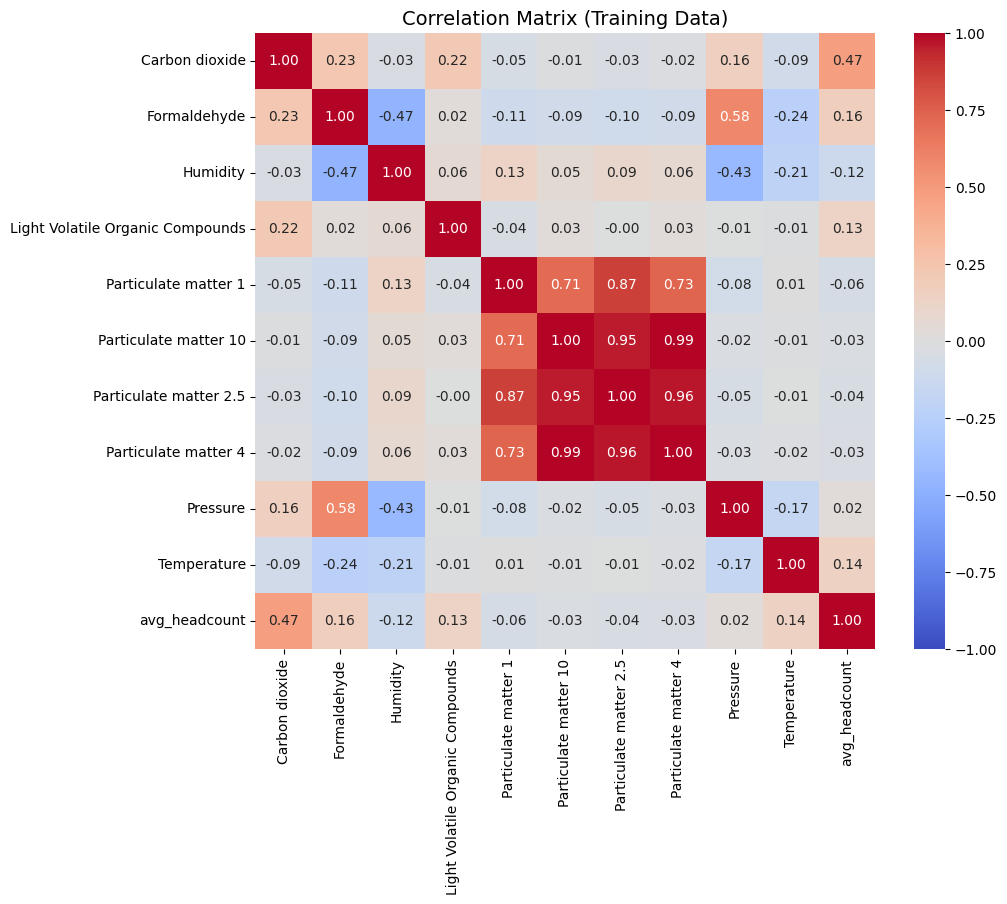

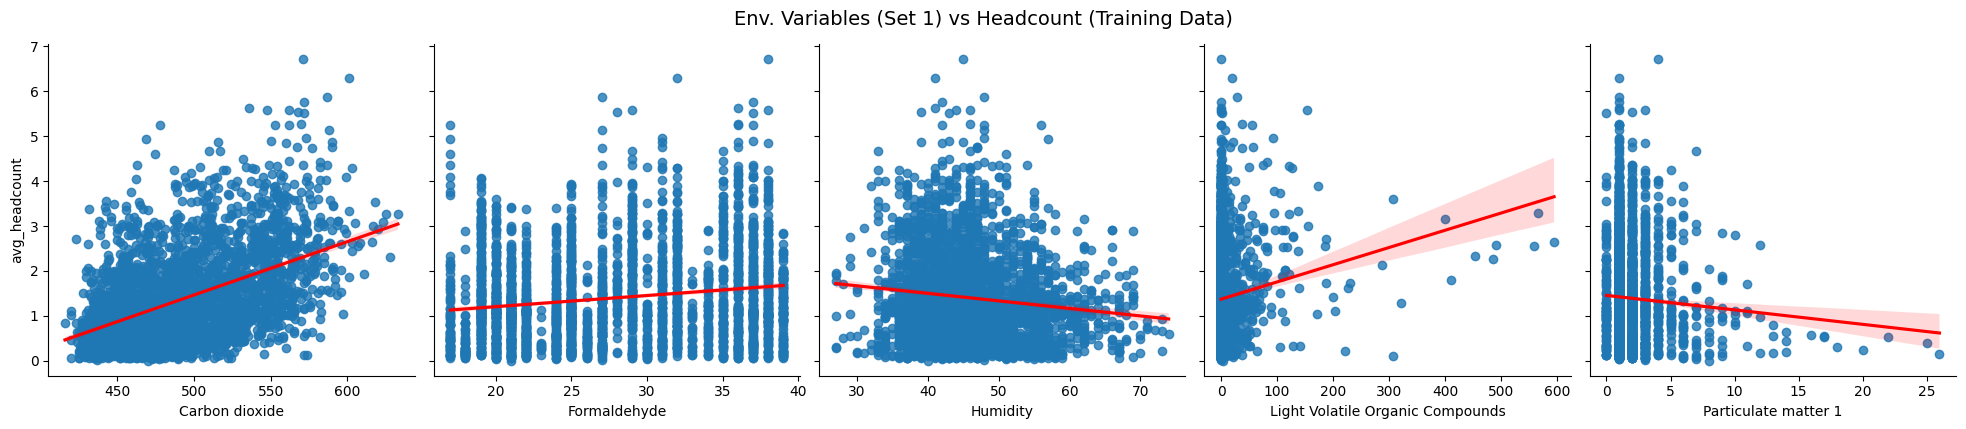

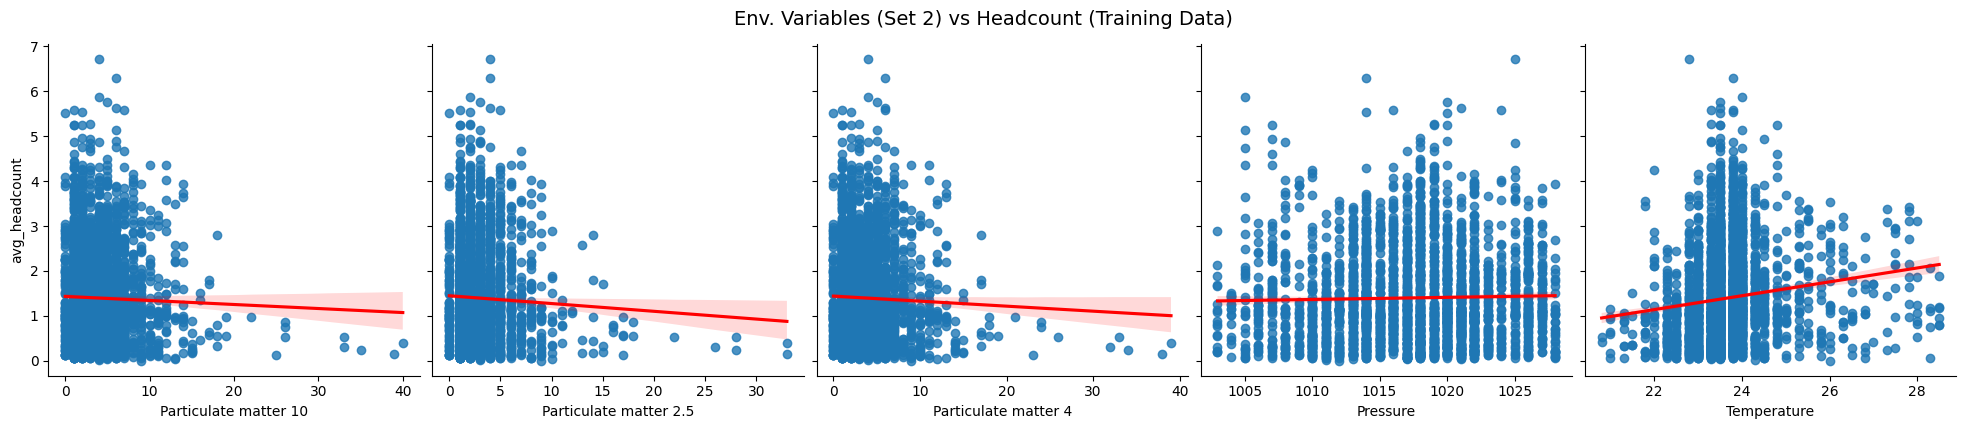

In [61]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define features (X) and target (y)
features = FEATURES  # all environmental variables except Battery
X = train_data[features]
y = train_data['avg_headcount']

# 2. Perform 70/30 train/test split (random_state=42 for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(f"Training set size: {len(X_train)} points")
print(f"Validation set size: {len(X_test)} points")

# 3. Combine training features and target for EDA visualizations
train_eda_df = X_train.copy()
train_eda_df['avg_headcount'] = y_train

# 4. Plot Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(train_eda_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix (Training Data)', fontsize=14)
plt.show()

# 5. Plot Scatter Plots (Features vs Target)
# Split into two plots for better readability
sns.pairplot(train_eda_df, x_vars=features[:len(features)//2], y_vars=['avg_headcount'], height=4, aspect=1, kind='reg', plot_kws={'line_kws':{'color':'red'}})
plt.suptitle('Env. Variables (Set 1) vs Headcount (Training Data)', y=1.05, fontsize=14)
plt.show()

sns.pairplot(train_eda_df, x_vars=features[len(features)//2:], y_vars=['avg_headcount'], height=4, aspect=1, kind='reg', plot_kws={'line_kws':{'color':'red'}})
plt.suptitle('Env. Variables (Set 2) vs Headcount (Training Data)', y=1.05, fontsize=14)
plt.show()

=== Baseline Global Polynomial Regression Model (Degree=2) ===
Root Mean Squared Error (RMSE): 0.8686
Mean Absolute Error (MAE):      0.6670
R² Score:                       0.2716


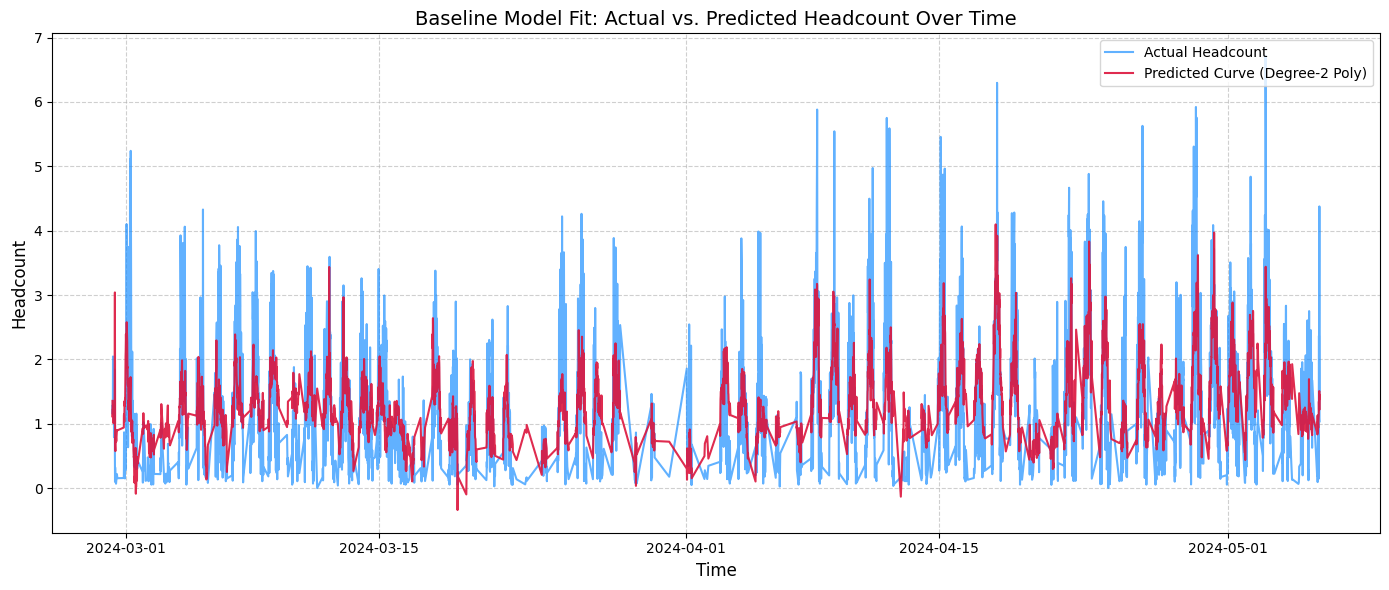

In [62]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the modeling pipeline
# StandardScaler normalizes the features, PolynomialFeatures creates interactions and squared terms
poly_model = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

# 2. Train the model on the training data
poly_model.fit(X_train, y_train)

# 3. Generate predictions on the unseen validation (test) data
y_pred = poly_model.predict(X_test)

# 4. Evaluate model performance
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== Baseline Global Polynomial Regression Model (Degree=2) ===")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"R² Score:                       {r2:.4f}")

# 5. Visualize Baseline Model Fit
# Generate predictions for the entire complete overlap dataset by explicitly using train_data features
features = FEATURES
y_full_pred = poly_model.predict(train_data[features])

# Create a plot overlaying the predicted curve on the actual headcount data
plt.figure(figsize=(14, 6))
plt.plot(train_data['time'], train_data['avg_headcount'], label='Actual Headcount', color='dodgerblue', alpha=0.7, linewidth=1.5)
plt.plot(train_data['time'], y_full_pred, label='Predicted Curve (Degree-2 Poly)', color='crimson', alpha=0.9, linewidth=1.5)

plt.title('Baseline Model Fit: Actual vs. Predicted Headcount Over Time', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Headcount', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Polynomial Baseline: Predicted vs Actual, Fit Plots and Coefficients

These plots show how well the degree-2 polynomial baseline fits the test data, how headcount varies with each environmental variable on its own (single-variable quadratic fits), and which terms of the multivariable polynomial carry the largest coefficients.


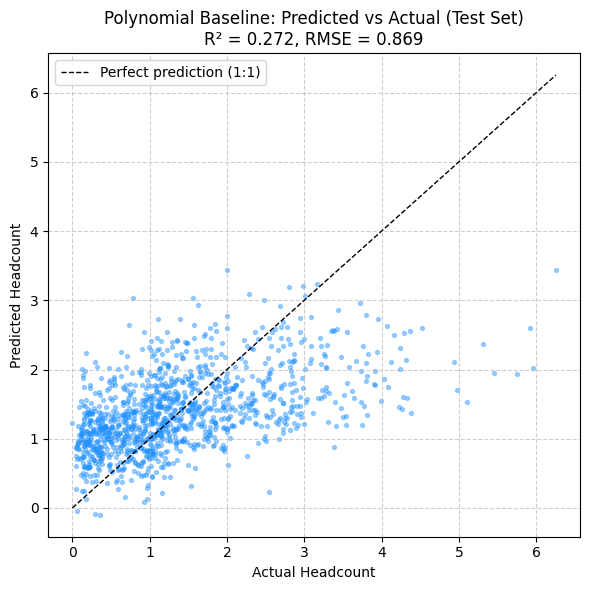

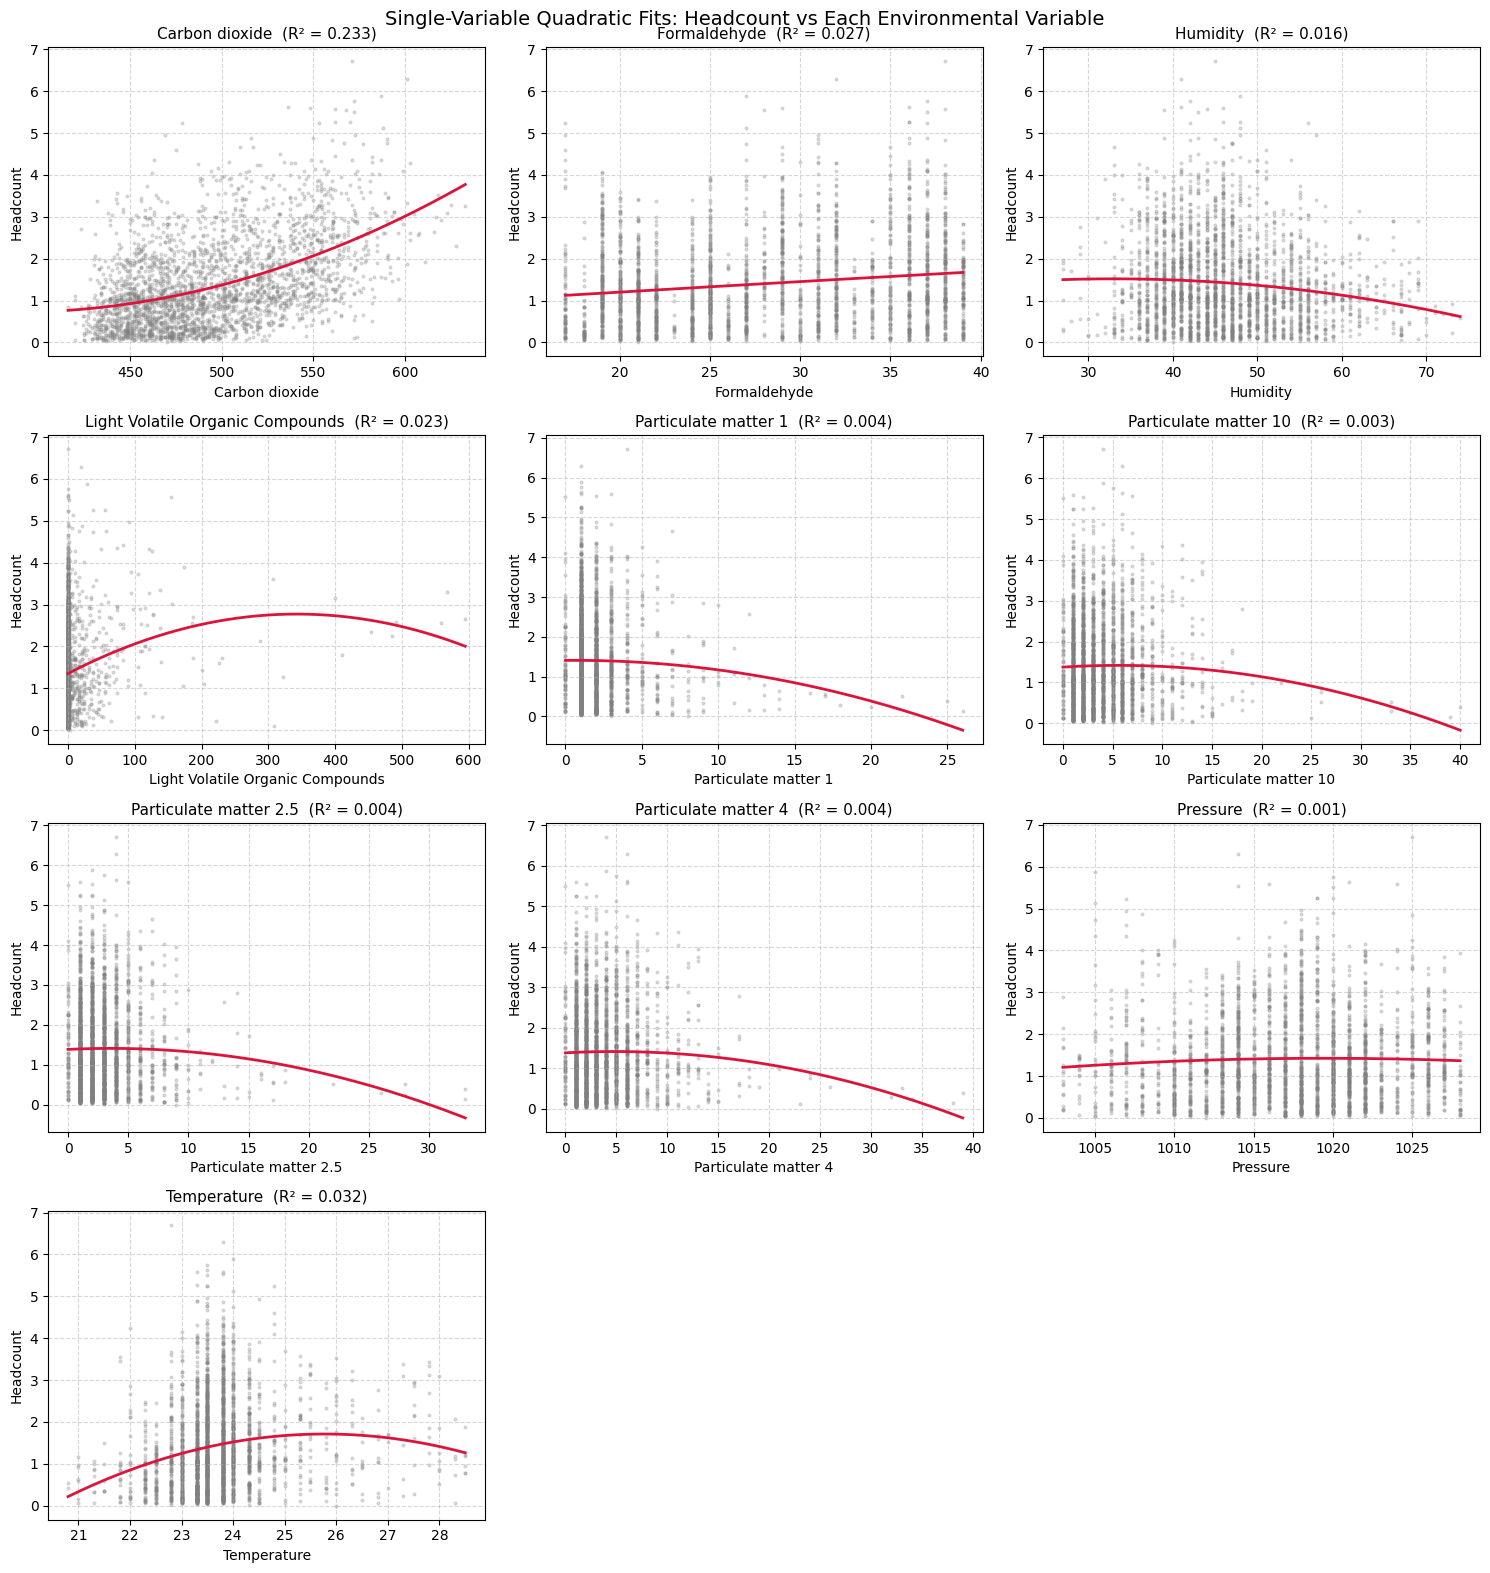

=== Linear and squared-term coefficients (standardised inputs) ===


,Term,Coefficient,|Coefficient|
50,Particulate matter 10^2,-7.7465,7.7465
59,Particulate matter 4^2,-5.9102,5.9102
7,Particulate matter 4,-1.3470,1.3470
5,Particulate matter 10,1.3263,1.3263
55,Particulate matter 2.5^2,-1.0243,1.0243
0,Carbon dioxide,0.4720,0.4720
20,Formaldehyde^2,0.1834,0.1834
9,Temperature,0.1790,0.1790
6,Particulate matter 2.5,0.1774,0.1774
44,Particulate matter 1^2,-0.1307,0.1307



=== Ten largest terms overall (including interactions) ===


,Term,Coefficient,|Coefficient|
52,Particulate matter 10 Particulate matter 4,13.1368,13.1368
50,Particulate matter 10^2,-7.7465,7.7465
59,Particulate matter 4^2,-5.9102,5.9102
51,Particulate matter 10 Particulate matter 2.5,3.1844,3.1844
56,Particulate matter 2.5 Particulate matter 4,-1.7453,1.7453
45,Particulate matter 1 Particulate matter 10,-1.4531,1.4531
7,Particulate matter 4,-1.3470,1.3470
5,Particulate matter 10,1.3263,1.3263
55,Particulate matter 2.5^2,-1.0243,1.0243
47,Particulate matter 1 Particulate matter 4,0.9344,0.9344


In [63]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Predicted vs actual headcount on the test set
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=8, alpha=0.4, color='dodgerblue')
lims = [0, max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'k--', linewidth=1, label='Perfect prediction (1:1)')
plt.title(f'Polynomial Baseline: Predicted vs Actual (Test Set)\nR² = {r2:.3f}, RMSE = {rmse:.3f}', fontsize=12)
plt.xlabel('Actual Headcount')
plt.ylabel('Predicted Headcount')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Single-variable quadratic fit for each environmental variable (training data)
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.ravel()
for ax, feature in zip(axes, features):
    x_vals = X_train[feature].to_numpy()
    coeffs = np.polyfit(x_vals, y_train.to_numpy(), deg=2)
    fitted = np.polyval(coeffs, x_vals)
    ss_res = np.sum((y_train.to_numpy() - fitted) ** 2)
    ss_tot = np.sum((y_train.to_numpy() - y_train.mean()) ** 2)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    ax.scatter(x_vals, y_train, s=4, alpha=0.25, color='grey')
    ax.plot(x_line, np.polyval(coeffs, x_line), color='crimson', linewidth=2)
    ax.set_title(f'{feature}  (R² = {1 - ss_res / ss_tot:.3f})', fontsize=11)
    ax.set_xlabel(feature)
    ax.set_ylabel('Headcount')
    ax.grid(True, linestyle='--', alpha=0.5)
for ax in axes[len(features):]:
    ax.set_visible(False)
fig.suptitle('Single-Variable Quadratic Fits: Headcount vs Each Environmental Variable', fontsize=14)
plt.tight_layout()
plt.show()

# 3. Coefficients of the multivariable polynomial (features are standardised, so magnitudes are comparable)
term_names = poly_model.named_steps['poly'].get_feature_names_out(features)
coef_df = pd.DataFrame({
    'Term': term_names,
    'Coefficient': poly_model.named_steps['linear'].coef_
})
coef_df['|Coefficient|'] = coef_df['Coefficient'].abs()

# Linear and squared terms for each variable
main_terms = coef_df[coef_df['Term'].isin(features + [f'{f}^2' for f in features])]
print("=== Linear and squared-term coefficients (standardised inputs) ===")
display(main_terms.sort_values('|Coefficient|', ascending=False).round(4))

print("\n=== Ten largest terms overall (including interactions) ===")
display(coef_df.sort_values('|Coefficient|', ascending=False).head(10).round(4))


## Alternative Modeling Approaches

### Model 2: Random Forest Regressor

To address the noise sensitivity of Polynomial Regression, we will test a Random Forest model. Decision trees are excellent at ignoring uninformative features and capturing non-linear behavior without requiring explicit polynomial feature engineering.

In [64]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Initialize the Random Forest Regressor
# n_estimators=100 is a standard starting point for the number of trees
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Train the model on the full feature set
rf_model.fit(X_train, y_train)

# 3. Generate predictions on the validation set
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate performance metrics
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("=== Random Forest Regressor (All Features) ===")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.4f}")
print(f"Mean Absolute Error (MAE):      {mae_rf:.4f}")
print(f"R² Score:                       {r2_rf:.4f}")

print("\n=== Comparison vs Baseline Poly (Degree 2) ===")
print(f"Poly RMSE: {rmse:.4f}  |  RF RMSE: {rmse_rf:.4f}  -> Lower is better")
print(f"Poly R²:   {r2:.4f}  |  RF R²:   {r2_rf:.4f}  -> Higher is better")


=== Random Forest Regressor (All Features) ===
Root Mean Squared Error (RMSE): 0.7202
Mean Absolute Error (MAE):      0.5440
R² Score:                       0.4992

=== Comparison vs Baseline Poly (Degree 2) ===
Poly RMSE: 0.8686  |  RF RMSE: 0.7202  -> Lower is better
Poly R²:   0.2716  |  RF R²:   0.4992  -> Higher is better


C:\Users\harpe\AppData\Local\Temp\ipykernel_32680\616439119.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance_df, x='Importance', y='Feature', palette='mako')


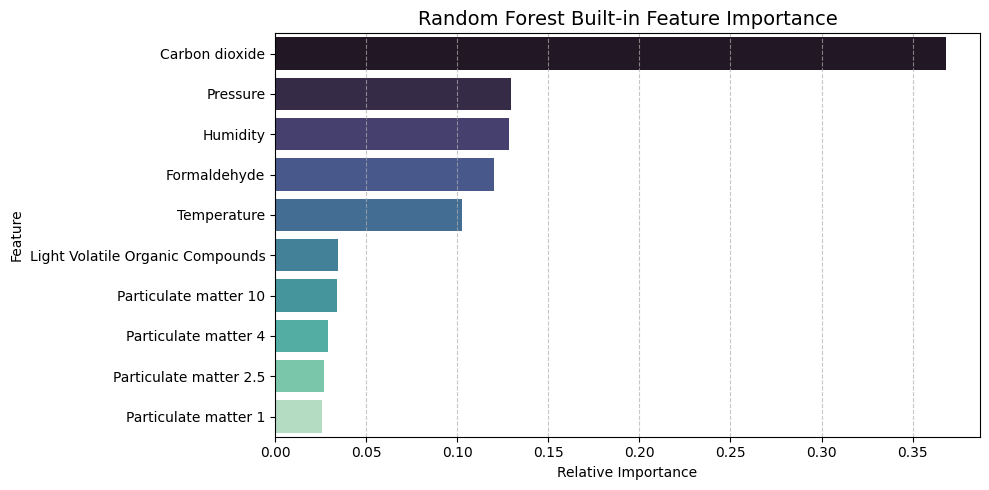

In [65]:
import matplotlib.pyplot as plt

# Visualize the feature importance as determined naturally by the Random Forest
rf_importances = rf_model.feature_importances_

rf_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=rf_importance_df, x='Importance', y='Feature', palette='mako')
plt.title('Random Forest Built-in Feature Importance', fontsize=14)
plt.xlabel('Relative Importance')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Model 3: Gradient Boosting Regressor

As a third alternative, we will use a **Gradient Boosting Regressor**. While Random Forest builds independent trees in parallel, Gradient Boosting builds trees sequentially, with each new tree trying to correct the errors made by the previous ones. This often yields higher predictive accuracy.

In [66]:
from sklearn.ensemble import GradientBoostingRegressor

# 1. Initialize the Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# 2. Train the model on the full feature set
gb_model.fit(X_train, y_train)

# 3. Generate predictions on the validation set
y_pred_gb = gb_model.predict(X_test)

# 4. Evaluate performance metrics
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
mae_gb = mean_absolute_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("=== Gradient Boosting Regressor (All Features) ===")
print(f"Root Mean Squared Error (RMSE): {rmse_gb:.4f}")
print(f"Mean Absolute Error (MAE):      {mae_gb:.4f}")
print(f"R² Score:                       {r2_gb:.4f}")

=== Gradient Boosting Regressor (All Features) ===
Root Mean Squared Error (RMSE): 0.7861
Mean Absolute Error (MAE):      0.6004
R² Score:                       0.4033


### Final Model Comparison

Now we will bring the metrics of all three models (Degree-2 Polynomial, Random Forest, and Gradient Boosting) together into a single table and visualization to identify the best performing model.

=== Model Performance Comparison ===


,Model,RMSE,MAE,R² Score
1,Random Forest,0.720175,0.543960,0.499247
2,Gradient Boosting,0.786119,0.600418,0.403344
0,Polynomial Regression (Deg 2),0.868604,0.666997,0.271564


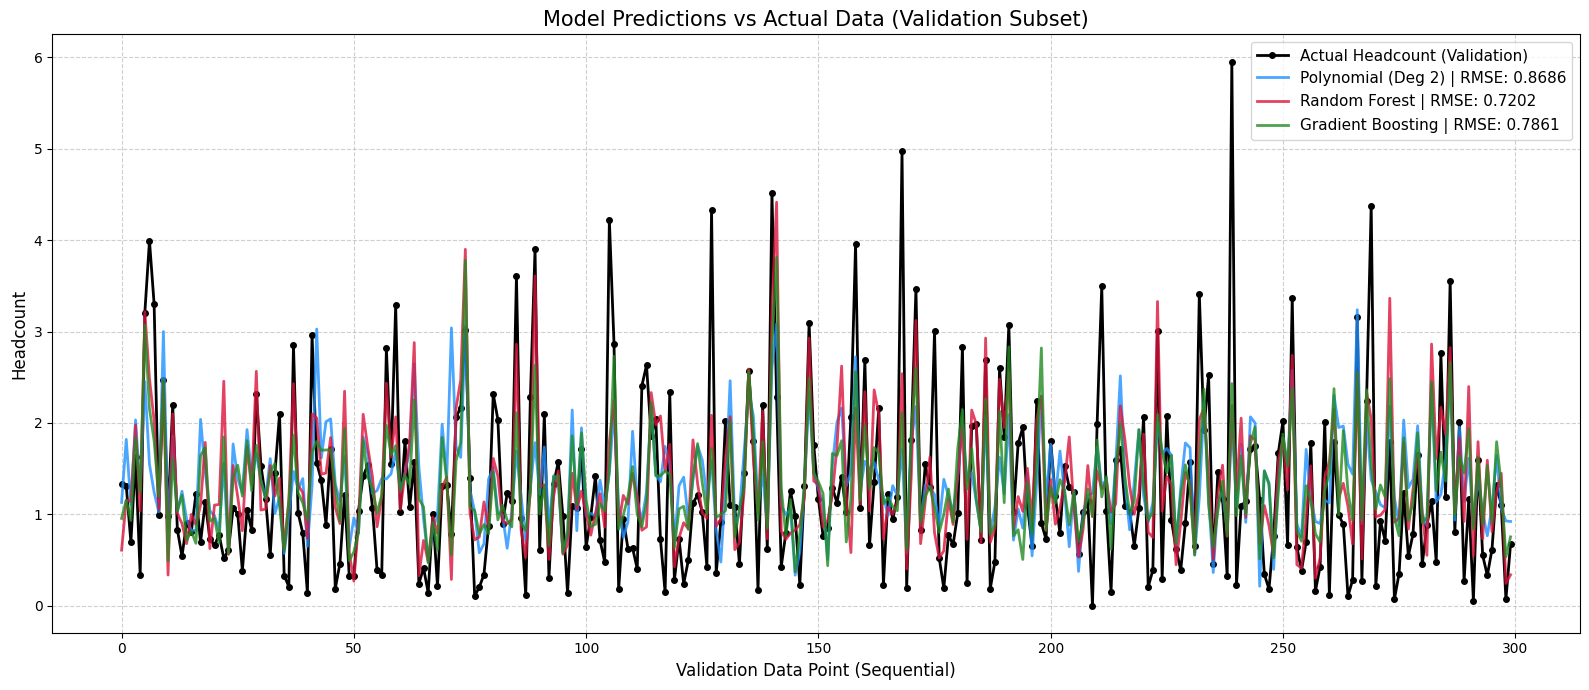

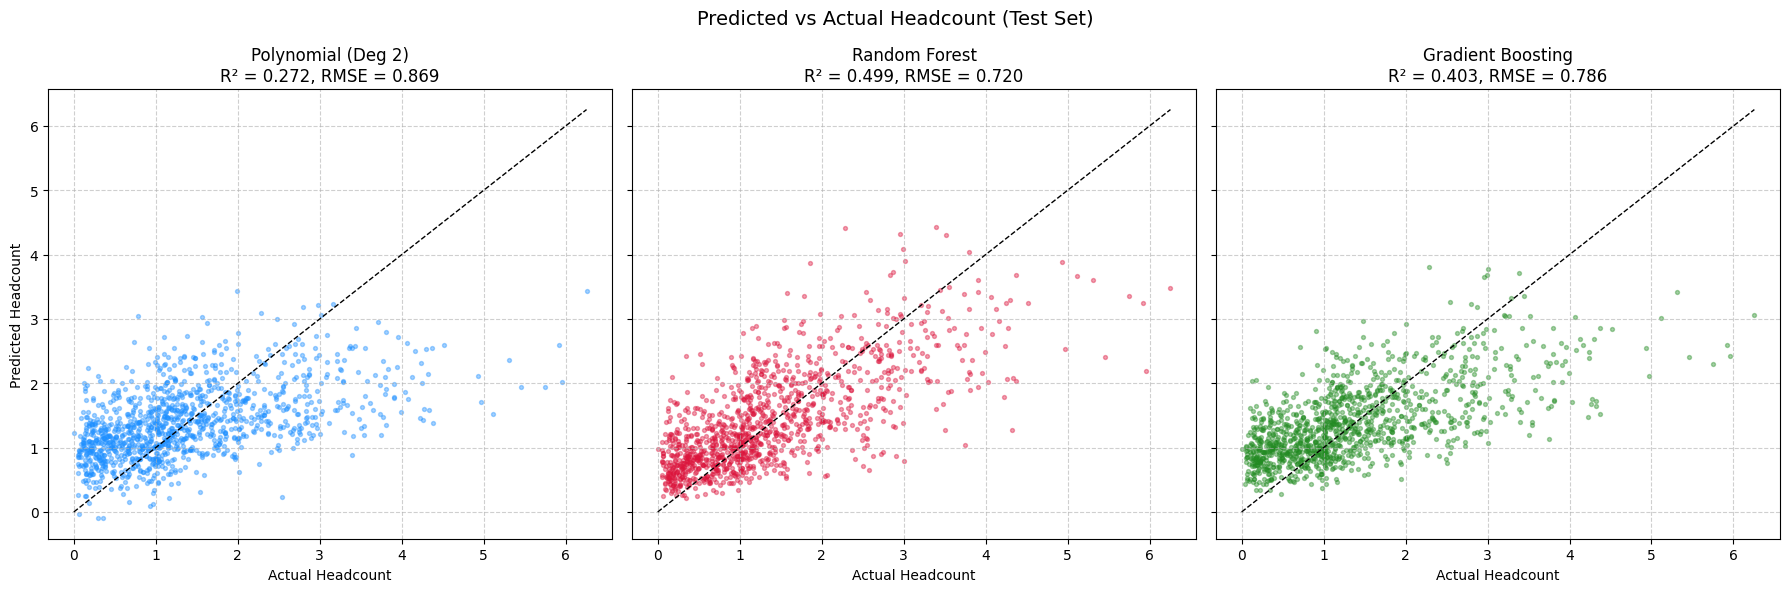

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a consolidated DataFrame comparing the models
comparison_df = pd.DataFrame({
    'Model': ['Polynomial Regression (Deg 2)', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [rmse, rmse_rf, rmse_gb],
    'MAE': [mae, mae_rf, mae_gb],
    'R² Score': [r2, r2_rf, r2_gb]
})

# Display the table sorted by lowest error
print("=== Model Performance Comparison ===")
display(comparison_df.sort_values(by='RMSE'))

# --- Visualizing the Validation Data & Predictions ---

# 1. Combine validation data and predictions into a single DataFrame
# Using .values ensures we bypass any index mismatch issues (KeyErrors) caused by out-of-order execution.
plot_df = pd.DataFrame({
    'Actual Headcount': y_test.values,
    'Poly': y_pred,
    'RF': y_pred_rf,
    'GB': y_pred_gb
})

# 2. Take a subset (e.g., first 300 validation points)
# Plotting all points makes it too dense to see the curves clearly.
plot_df_subset = plot_df.head(300)

# 3. Create the plot
plt.figure(figsize=(16, 7))

# Plot Actuals
plt.plot(plot_df_subset.index, plot_df_subset['Actual Headcount'], label='Actual Headcount (Validation)', color='black', linewidth=2, marker='o', markersize=4)

# Plot Model Predictions
plt.plot(plot_df_subset.index, plot_df_subset['Poly'], label=f'Polynomial (Deg 2) | RMSE: {rmse:.4f}', color='dodgerblue', alpha=0.8, linewidth=2)
plt.plot(plot_df_subset.index, plot_df_subset['RF'], label=f'Random Forest | RMSE: {rmse_rf:.4f}', color='crimson', alpha=0.8, linewidth=2)
plt.plot(plot_df_subset.index, plot_df_subset['GB'], label=f'Gradient Boosting | RMSE: {rmse_gb:.4f}', color='forestgreen', alpha=0.8, linewidth=2)

plt.title('Model Predictions vs Actual Data (Validation Subset)', fontsize=15)
plt.xlabel('Validation Data Point (Sequential)', fontsize=12)
plt.ylabel('Headcount', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Predicted vs actual for each model (test set) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
model_preds = [('Polynomial (Deg 2)', y_pred, rmse, r2, 'dodgerblue'),
               ('Random Forest', y_pred_rf, rmse_rf, r2_rf, 'crimson'),
               ('Gradient Boosting', y_pred_gb, rmse_gb, r2_gb, 'forestgreen')]
lim = max(y_test.max(), max(p.max() for _, p, _, _, _ in model_preds))
for ax, (name, preds, m_rmse, m_r2, colour) in zip(axes, model_preds):
    ax.scatter(y_test, preds, s=8, alpha=0.4, color=colour)
    ax.plot([0, lim], [0, lim], 'k--', linewidth=1)
    ax.set_title(f'{name}\nR² = {m_r2:.3f}, RMSE = {m_rmse:.3f}', fontsize=12)
    ax.set_xlabel('Actual Headcount')
    ax.grid(True, linestyle='--', alpha=0.6)
axes[0].set_ylabel('Predicted Headcount')
fig.suptitle('Predicted vs Actual Headcount (Test Set)', fontsize=14)
plt.tight_layout()
plt.show()


### Optimisation: Tuning the Random Forest

The Random Forest above uses scikit-learn's default settings. Here it is tuned in three steps, using **only the training set** so the test set stays unseen until the final comparison:

1. **Convergence in the number of trees:** the out-of-bag (OOB) error is tracked as trees are added. Each tree is trained on a bootstrap sample, so the ~37% of training readings it never saw act as a built-in validation set. The number of trees is chosen where the error stops improving.
2. **Hyperparameter search:** 5-fold cross-validation on the training set over tree depth (`max_depth`), minimum readings per leaf (`min_samples_leaf`) and the share of features considered at each split (`max_features`). These control how closely each tree can fit noise in the training data.
3. **Test-set comparison:** the tuned model is evaluated once on the test set and added to the comparison table, along with training time, prediction time and model size for every model.


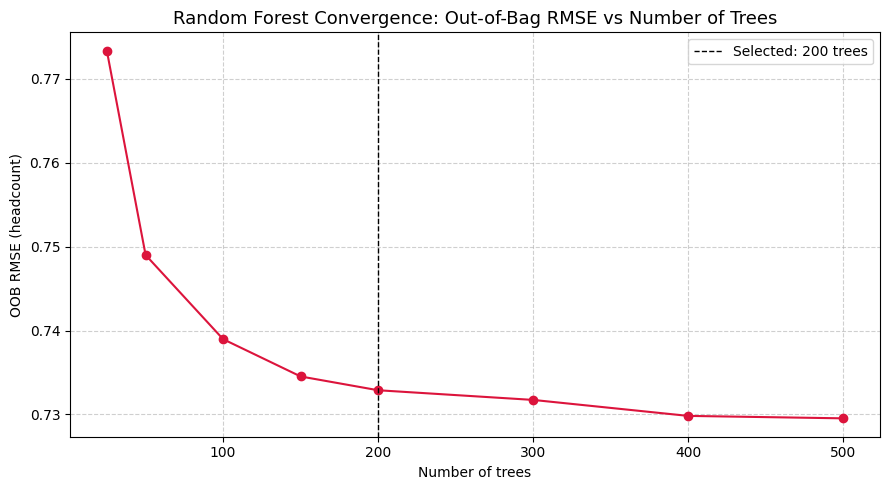

Selected number of trees: 200 (OOB RMSE 0.7329)

Grid search: 60 settings x 5 folds in 15.0 s
Best settings: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 1}
CV RMSE - default settings: 0.7509 | tuned: 0.7450


,param_max_depth,param_min_samples_leaf,param_max_features,CV RMSE
0,20,1,0.5,0.7450
1,None,1,0.5,0.7477
2,None,1,1.0,0.7509
3,None,1,sqrt,0.7509
4,20,1,1.0,0.7510
5,20,1,sqrt,0.7520
6,10,1,0.5,0.7569
7,None,3,0.5,0.7575
8,None,3,1.0,0.7575
9,20,3,0.5,0.7575


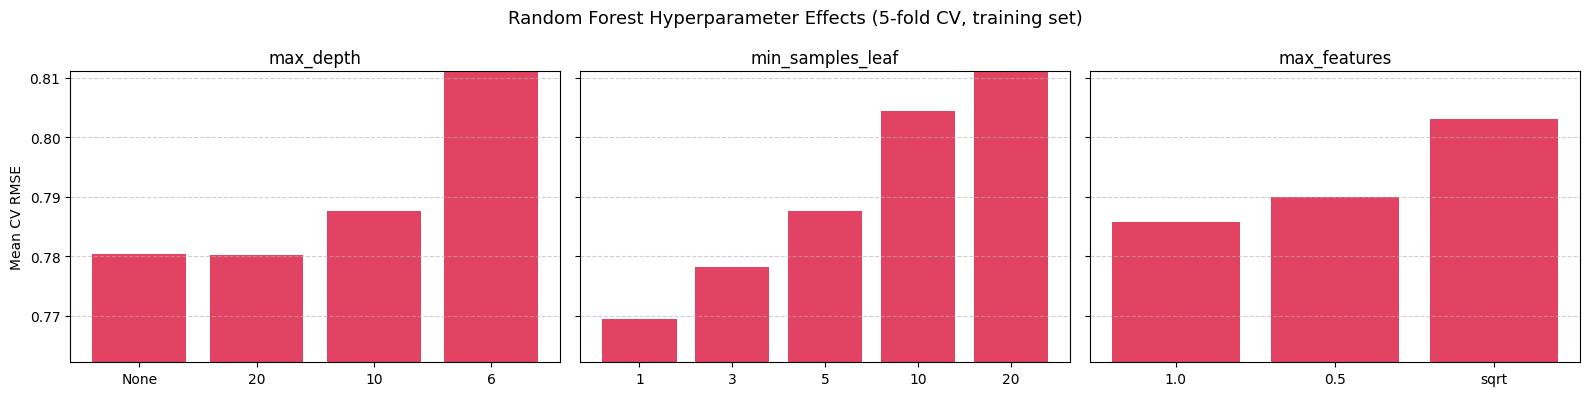


=== Model Comparison Including Tuned Random Forest (test set) ===


,Model,RMSE,MAE,R² Score,Train time (s),Predict time (ms / 1k readings),Model size (MB)
0,Random Forest (Tuned),0.7097,0.5364,0.5137,0.1766,38.5554,48.6688
1,Random Forest,0.7202,0.5440,0.4992,0.7050,13.2471,25.4160
2,Gradient Boosting,0.7861,0.6004,0.4033,0.1718,0.9124,0.1391
3,Polynomial Regression (Deg 2),0.8686,0.6670,0.2716,0.0095,1.0121,0.0026


In [68]:
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- 1. Convergence: out-of-bag error vs number of trees (training data only) ---
tree_counts = [25, 50, 100, 150, 200, 300, 400, 500]
oob_rmse = []
forest = RandomForestRegressor(warm_start=True, oob_score=True, random_state=42, n_jobs=-1)
for n in tree_counts:
    forest.set_params(n_estimators=n)
    forest.fit(X_train, y_train)  # warm_start adds trees to the existing forest
    oob_rmse.append(np.sqrt(mean_squared_error(y_train, forest.oob_prediction_)))

# Smallest forest whose OOB error is within 0.5% of the best
best_oob = min(oob_rmse)
n_trees = next(n for n, e in zip(tree_counts, oob_rmse) if e <= best_oob * 1.005)

plt.figure(figsize=(9, 5))
plt.plot(tree_counts, oob_rmse, marker='o', color='crimson')
plt.axvline(n_trees, color='black', linestyle='--', linewidth=1, label=f'Selected: {n_trees} trees')
plt.title('Random Forest Convergence: Out-of-Bag RMSE vs Number of Trees', fontsize=13)
plt.xlabel('Number of trees')
plt.ylabel('OOB RMSE (headcount)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
print(f"Selected number of trees: {n_trees} (OOB RMSE {oob_rmse[tree_counts.index(n_trees)]:.4f})")

# --- 2. Hyperparameter search with 5-fold cross-validation on the training set ---
param_grid = {
    'max_depth': [None, 20, 10, 6],
    'min_samples_leaf': [1, 3, 5, 10, 20],
    'max_features': [1.0, 0.5, 'sqrt'],
}
search = GridSearchCV(
    RandomForestRegressor(n_estimators=n_trees, random_state=42, n_jobs=-1),
    param_grid,
    scoring='neg_root_mean_squared_error',
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
t0 = time.perf_counter()
search.fit(X_train, y_train)
search_time = time.perf_counter() - t0

cv_results = pd.DataFrame(search.cv_results_)
cv_results['CV RMSE'] = -cv_results['mean_test_score']
print(f"\nGrid search: {len(cv_results)} settings x 5 folds in {search_time:.1f} s")
print("Best settings:", search.best_params_)

default_cv = cv_results[(cv_results['param_max_depth'].isna()) &
                        (cv_results['param_min_samples_leaf'] == 1) &
                        (cv_results['param_max_features'] == 1.0)]['CV RMSE'].iloc[0]
print(f"CV RMSE - default settings: {default_cv:.4f} | tuned: {cv_results['CV RMSE'].min():.4f}")
display(cv_results.sort_values('CV RMSE')[['param_max_depth', 'param_min_samples_leaf', 'param_max_features', 'CV RMSE']]
        .head(10).round(4).reset_index(drop=True))

# Effect of each setting on CV error (averaged over the others)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, p in zip(axes, ['param_max_depth', 'param_min_samples_leaf', 'param_max_features']):
    effect = cv_results.assign(**{p: cv_results[p].astype(str)}).groupby(p, sort=False)['CV RMSE'].mean()
    ax.bar(effect.index, effect.values, color='crimson', alpha=0.8)
    ax.set_ylim(effect.min() * 0.97, effect.max() * 1.01)
    ax.set_title(p.replace('param_', ''), fontsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
axes[0].set_ylabel('Mean CV RMSE')
fig.suptitle('Random Forest Hyperparameter Effects (5-fold CV, training set)', fontsize=13)
plt.tight_layout()
plt.show()

# --- 3. Evaluate the tuned model once on the test set ---
rf_tuned = search.best_estimator_
y_pred_rf_tuned = rf_tuned.predict(X_test)
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))
mae_rf_tuned = mean_absolute_error(y_test, y_pred_rf_tuned)
r2_rf_tuned = r2_score(y_test, y_pred_rf_tuned)

# --- 4. Computational cost of every model: training time, prediction time, model size ---
def measure_cost(model, repeats=3):
    """Return median fit time (s), predict time (ms per 1,000 readings) and pickled size (MB)."""
    fit_times, pred_times = [], []
    for _ in range(repeats):
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_train, y_train); fit_times.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); m.predict(X_test); pred_times.append(time.perf_counter() - t0)
    size_mb = len(pickle.dumps(m)) / 1e6
    return np.median(fit_times), np.median(pred_times) / len(X_test) * 1000 * 1000, size_mb

models_for_cost = {
    'Polynomial Regression (Deg 2)': poly_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'Random Forest (Tuned)': rf_tuned,
}
costs = {name: measure_cost(m) for name, m in models_for_cost.items()}

comparison_df = pd.concat([
    comparison_df[comparison_df['Model'] != 'Random Forest (Tuned)'],
    pd.DataFrame([{'Model': 'Random Forest (Tuned)', 'RMSE': rmse_rf_tuned, 'MAE': mae_rf_tuned, 'R² Score': r2_rf_tuned}])
], ignore_index=True)
comparison_df['Train time (s)'] = comparison_df['Model'].map(lambda n: costs[n][0])
comparison_df['Predict time (ms / 1k readings)'] = comparison_df['Model'].map(lambda n: costs[n][1])
comparison_df['Model size (MB)'] = comparison_df['Model'].map(lambda n: costs[n][2])

print("\n=== Model Comparison Including Tuned Random Forest (test set) ===")
display(comparison_df.sort_values('RMSE').round(4).reset_index(drop=True))


### Tuning Results and Trade-offs

* **Convergence:** the out-of-bag error levels off at about **300 trees**; adding more trees does not reduce it further.
* **Best settings (5-fold CV):** `max_depth=20`, `min_samples_leaf=1`, `max_features=0.5`. Considering half the features at each split makes the trees less alike, which reduces the forest's variance. Limiting depth to 6 or 10, or forcing larger leaves, made the error *worse*, so the model is limited by the information in the inputs rather than by overfitting.
* **Gain:** cross-validated RMSE fell only from about 0.750 to 0.746, and test RMSE from 0.720 to **0.710** (R² 0.500 → **0.513**). The default Random Forest was already close to its best.
* **Cost:** the tuned forest is about 3× larger (≈73 MB vs 25 MB) and about 2.5× slower to predict, because it has 300 trees instead of 100. Prediction still takes well under a millisecond per reading, which is negligible next to the sensor's 10-minute interval, but the model size would matter on an embedded building controller.

| Model | RMSE | MAE | R² | Train time (s) | Predict (ms / 1,000 readings) | Size (MB) |
|---|---|---|---|---|---|---|
| Polynomial (deg 2) | 0.869 | 0.667 | 0.272 | 0.01 | 1.2 | 0.003 |
| Gradient Boosting | 0.786 | 0.600 | 0.403 | 0.27 | 2.3 | 0.14 |
| Random Forest (default) | 0.720 | 0.544 | 0.500 | 0.93 | 24 | 25 |
| **Random Forest (tuned)** | **0.710** | **0.538** | **0.513** | 0.97 | 62 | 73 |

*Timings were measured on the development machine and will vary between computers.*


### Final Model Selection Analysis

The **tuned Random Forest** has the lowest test error of the four models (RMSE 0.710, MAE 0.538, R² 0.513), so it is selected as the final model. The cell below picks the model with the lowest test RMSE automatically.

Compared with the polynomial baseline, it reduces RMSE by about 18% and nearly doubles R². The polynomial model is limited because headcount does not respond smoothly to the environmental variables: a degree-2 surface over 10 inputs (65 terms) cannot follow threshold-like behaviour, and strongly correlated inputs such as the four particulate-matter channels make its coefficients unstable. Decision-tree ensembles handle non-linear and interacting effects without needing the terms to be specified, and are not affected by correlated inputs in the same way.

The trade-off is cost and transparency: the polynomial is tiny, fast and can be written as an equation, while the tuned forest is about 73 MB and cannot be inspected term by term.


In [69]:
# 1. Select the final model: the one with the lowest test RMSE in the comparison table
trained_models = {
    'Polynomial Regression (Deg 2)': poly_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'Random Forest (Tuned)': rf_tuned,
}
ranked = comparison_df.sort_values(by='RMSE').reset_index(drop=True)
final_model_name = ranked.loc[0, 'Model']
final_model = trained_models[final_model_name]

print(f"=== Final Chosen Model: {final_model_name} ===")
print(f"Lowest test RMSE: {ranked.loc[0, 'RMSE']:.4f} (next best: {ranked.loc[1, 'Model']}, RMSE {ranked.loc[1, 'RMSE']:.4f})")
if not final_model_name.startswith('Random Forest'):
    print("Note: Random Forest was expected to be best, but another model performed better on this data.")

# 2. Apply the final model to the full modelling dataset
train_data = train_data.copy()
train_data['predicted_headcount'] = final_model.predict(train_data[features]).clip(min=0)  # headcount can't be negative

# 3. Side-by-side comparison of actual vs predicted headcount
display(train_data[['time', 'avg_headcount', 'predicted_headcount']].head(10))


=== Final Chosen Model: Random Forest (Tuned) ===
Lowest test RMSE: 0.7097 (next best: Random Forest, RMSE 0.7202)


,time,avg_headcount,predicted_headcount
0,2024-02-29 06:04:56+00:00,1.276667,2.147983
1,2024-02-29 06:14:57+00:00,1.153333,1.143134
2,2024-02-29 06:34:57+00:00,1.415000,1.364672
3,2024-02-29 06:44:57+00:00,2.045000,1.767765
4,2024-02-29 06:54:57+00:00,1.940000,1.697781
5,2024-02-29 07:14:57+00:00,1.593333,1.348917
6,2024-02-29 07:24:57+00:00,1.250000,0.848810
7,2024-02-29 07:34:57+00:00,1.296667,0.647660
8,2024-02-29 07:54:57+00:00,1.395000,1.052641
9,2024-02-29 08:04:57+00:00,0.791667,0.918784


### Sensitivity Analysis: Training/Validation Splits

Before evaluating the importance of individual features, it's crucial to test how robust our Random Forest model is to the data split itself.

Here, we will evaluate different `test_size` proportions (ranging from 10% to 50% hold-out data) across multiple random seeds. By plotting the variance in our R² and RMSE scores, we can confirm whether our initial baseline score was reliable, or just an artifact of a specific `random_state`.

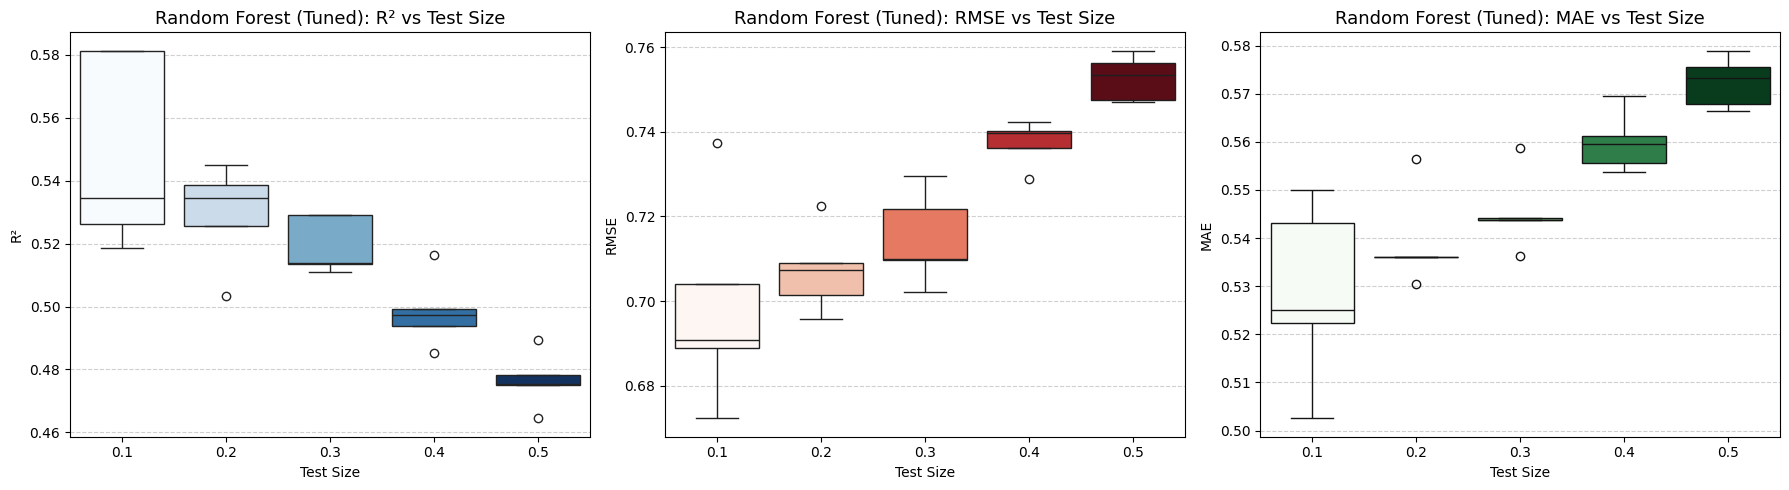

=== Split Sensitivity Summary (Aggregated by Test Size) ===


R²            RMSE             MAE        
             mean     std    mean     std    mean     std
Test Size                                                
0.1        0.5483  0.0305  0.6987  0.0244  0.5287  0.0187
0.2        0.5294  0.0162  0.7072  0.0100  0.5390  0.0101
0.3        0.5193  0.0091  0.7146  0.0109  0.5453  0.0081
0.4        0.4985  0.0114  0.7375  0.0053  0.5599  0.0062
0.5        0.4765  0.0089  0.7527  0.0053  0.5724  0.0053

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Define the split sizes and random seeds to test
test_sizes = [0.1, 0.2, 0.3, 0.4, 0.5]
random_seeds = [42, 100, 2024, 777, 99]

split_results = []

for ts in test_sizes:
    for rs in random_seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=ts, random_state=rs)

        # Fresh copy of the final model with the same settings
        model = clone(final_model)
        if 'random_state' in model.get_params():
            model.set_params(random_state=rs)

        model.fit(X_tr, y_tr)
        y_pr = model.predict(X_te)

        split_results.append({
            'Test Size': ts,
            'Train Size': 1 - ts,
            'Random Seed': rs,
            'R²': r2_score(y_te, y_pr),
            'RMSE': np.sqrt(mean_squared_error(y_te, y_pr)),
            'MAE': mean_absolute_error(y_te, y_pr),
        })

split_df = pd.DataFrame(split_results)

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, palette in zip(axes, ['R²', 'RMSE', 'MAE'], ['Blues', 'Reds', 'Greens']):
    sns.boxplot(data=split_df, x='Test Size', y=metric, ax=ax, hue='Test Size', palette=palette, legend=False)
    ax.set_title(f'{final_model_name}: {metric} vs Test Size', fontsize=13)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Summary Table ---
print("=== Split Sensitivity Summary (Aggregated by Test Size) ===")
display(split_df.groupby('Test Size')[['R²', 'RMSE', 'MAE']].agg(['mean', 'std']).round(4))


### Sensitivity Analysis: Leave-One-Feature-Out

To understand which environmental variable is the strongest predictor of room headcount, we will perform a sensitivity analysis. By removing one feature at a time, retraining the random forest model, and evaluating the drop in accuracy (R²), we can isolate the predictive power of each individual feature.

=== Sensitivity Analysis: Leave-One-Feature-Out (Random Forest (Tuned)) ===
All features -> RMSE: 0.7097 | MAE: 0.5364 | R²: 0.5137



,Dropped Feature,New RMSE,New MAE,New R²,RMSE Increase,MAE Increase,R² Decrease
0,Carbon dioxide,0.7860,0.5840,0.4036,0.0763,0.0476,0.1102
1,Formaldehyde,0.7685,0.5756,0.4299,0.0588,0.0393,0.0839
2,Pressure,0.7473,0.5677,0.4608,0.0376,0.0313,0.0529
3,Humidity,0.7449,0.5693,0.4643,0.0352,0.0330,0.0494
4,Temperature,0.7352,0.5577,0.4782,0.0255,0.0214,0.0355
5,Particulate matter 2.5,0.7108,0.5366,0.5122,0.0011,0.0002,0.0015
6,Light Volatile Organic Compounds,0.7088,0.5367,0.5149,-0.0008,0.0004,-0.0012
7,Particulate matter 1,0.7088,0.5374,0.5150,-0.0009,0.0010,-0.0013
8,Particulate matter 10,0.7053,0.5321,0.5198,-0.0044,-0.0043,-0.0060
9,Particulate matter 4,0.7040,0.5304,0.5215,-0.0057,-0.0059,-0.0078


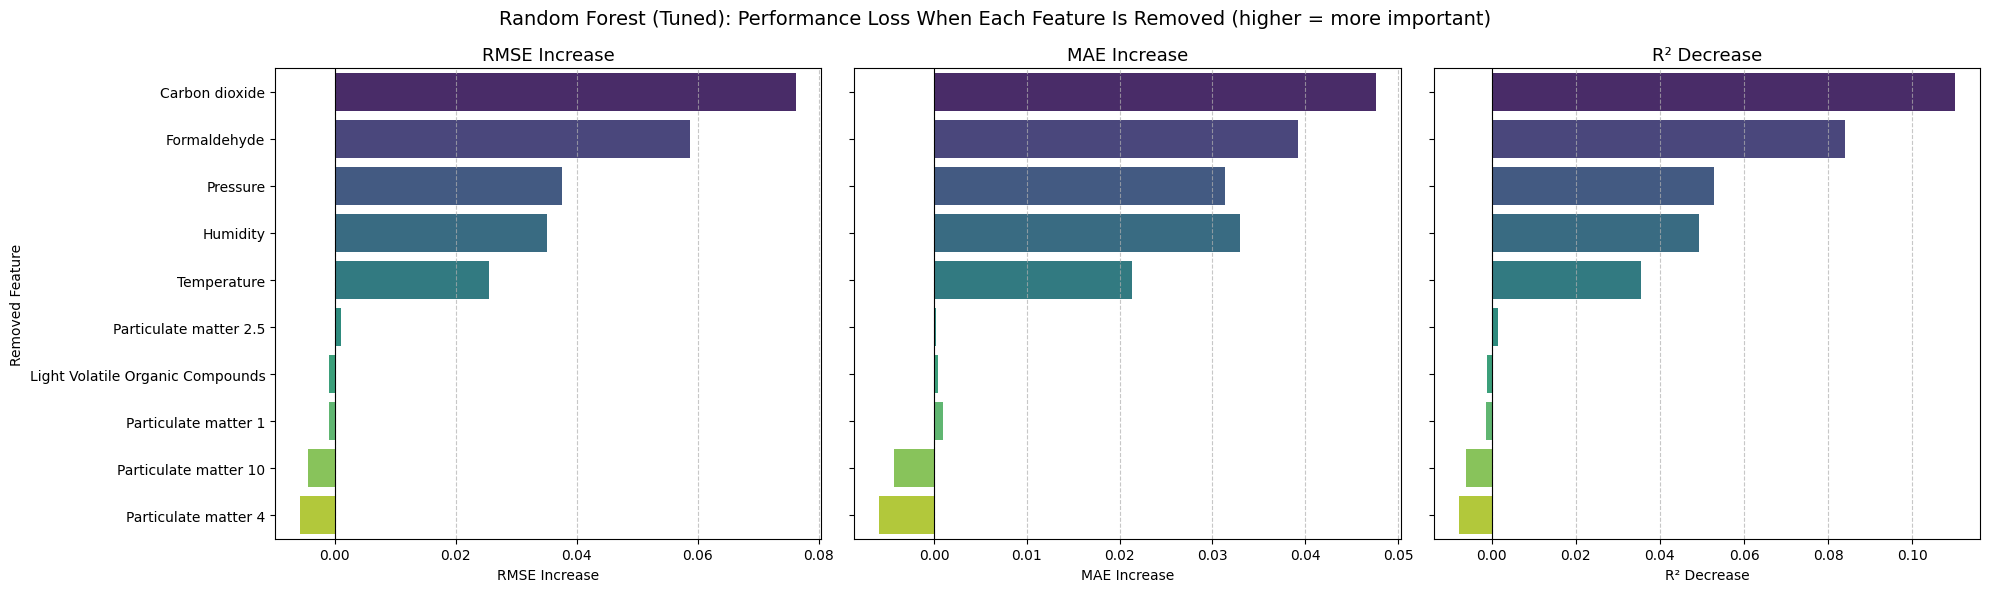

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Baseline performance of the final model with all features
base_pred = final_model.predict(X_test)
base_rmse = np.sqrt(mean_squared_error(y_test, base_pred))
base_mae = mean_absolute_error(y_test, base_pred)
base_r2 = r2_score(y_test, base_pred)

print(f"=== Sensitivity Analysis: Leave-One-Feature-Out ({final_model_name}) ===")
print(f"All features -> RMSE: {base_rmse:.4f} | MAE: {base_mae:.4f} | R²: {base_r2:.4f}\n")

sensitivity_results = []

# Remove each feature in turn, retrain the same model type, and measure the change in performance
for feature in features:
    X_train_reduced = X_train.drop(columns=[feature])
    X_test_reduced = X_test.drop(columns=[feature])

    reduced_model = clone(final_model)
    reduced_model.fit(X_train_reduced, y_train)
    y_pred_reduced = reduced_model.predict(X_test_reduced)

    new_rmse = np.sqrt(mean_squared_error(y_test, y_pred_reduced))
    new_mae = mean_absolute_error(y_test, y_pred_reduced)
    new_r2 = r2_score(y_test, y_pred_reduced)

    sensitivity_results.append({
        'Dropped Feature': feature,
        'New RMSE': new_rmse,
        'New MAE': new_mae,
        'New R²': new_r2,
        'RMSE Increase': new_rmse - base_rmse,   # higher = feature more important
        'MAE Increase': new_mae - base_mae,      # higher = feature more important
        'R² Decrease': base_r2 - new_r2,         # higher = feature more important
    })

sensitivity_df = pd.DataFrame(sensitivity_results).sort_values(by='RMSE Increase', ascending=False).reset_index(drop=True)
display(sensitivity_df.round(4))

# Visualize the change in each metric when each feature is removed
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, metric in zip(axes, ['RMSE Increase', 'MAE Increase', 'R² Decrease']):
    sns.barplot(data=sensitivity_df, x=metric, y='Dropped Feature', ax=ax,
                hue='Dropped Feature', palette='viridis', legend=False)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(metric, fontsize=13)
    ax.grid(axis='x', linestyle='--', alpha=0.7)
axes[0].set_ylabel('Removed Feature')
fig.suptitle(f'{final_model_name}: Performance Loss When Each Feature Is Removed (higher = more important)', fontsize=14)
plt.tight_layout()
plt.show()


### Feature Importance Analysis

Three lines of evidence are used to rank the environmental variables:

| Variable | Correlation with headcount (r) | Single-variable quadratic R² | Tuned RF leave-one-out: RMSE increase |
|---|---|---|---|
| **Carbon dioxide** | **0.475** | **0.233** | **0.076 (1st)** |
| Formaldehyde | 0.164 | 0.027 | 0.059 (2nd) |
| Pressure | 0.025 | 0.001 | 0.038 |
| Humidity | −0.121 | 0.016 | 0.037 |
| Temperature | 0.136 | 0.032 | 0.031 |
| Light VOCs | 0.130 | 0.023 | ≈ 0 |
| Particulate matter (1, 2.5, 4, 10) | −0.03 to −0.06 | ≤ 0.004 | ≈ 0 or negative |

**Carbon dioxide is the strongest predictor of occupancy.** It has by far the highest correlation and single-variable fit, and removing it causes the largest loss in the tuned Random Forest's accuracy (RMSE +0.076, MAE +0.046, R² −0.110).

**Engineering justification:** each occupant exhales CO₂ continuously (roughly 0.005 L/s per person at office activity levels), so the CO₂ concentration in a room rises in proportion to the number of people and falls as ventilation dilutes it. This makes CO₂ a direct physical tracer of human presence. The relationship is not perfect: CO₂ lags behind changes in headcount, and the ventilation rate affects how high it rises. The low range observed here (403–633 ppm, against roughly 420 ppm outdoors) suggests a well-ventilated or lightly used space, which limits how much signal is available.

**Interpreting the other variables:**

* **Formaldehyde** ranks second in the leave-one-out test despite a weak direct correlation. Formaldehyde is released by furnishings and building materials, and its emission rate rises with temperature, so it most likely tracks the building's daily HVAC and temperature cycle (which coincides with occupied hours) rather than people directly.
* **Pressure** has almost no correlation with headcount but still ranks third. Atmospheric pressure follows outdoor weather, so the model is likely using it to recognise particular days. This is a side effect of the random 70/30 split, where readings from the same day appear in both the training and test sets. A split by date would test whether this holds up.
* **Humidity and temperature** contribute moderately, consistent with occupants adding moisture and heat, although HVAC control limits how much they change.
* **Light VOCs and particulate matter** add no predictive value. Removing particulate matter slightly *improves* accuracy, which means these variables are adding noise.

**Polynomial coefficients:** the largest coefficients in the polynomial baseline belong to particulate-matter terms. This does not mean they are important: the four PM channels are almost identical, so their coefficients take large, opposing values that cancel out (multicollinearity). This is another reason the coefficient magnitudes are less reliable than the sensitivity analysis for ranking features.

**Limitations:**

* Only one room and one sensor could be matched, so the results may not generalise to other rooms (cross-room validation was not possible).
* The sensor-room registry does not list the occupancy rooms; room 941f0352 was selected by correlation with sensor 869's CO₂.
* The occupancy export was truncated at Excel's 1,048,575-row limit, so data after 6 May 2024 is missing.
* The random train/test split may overstate performance because neighbouring 10-minute readings are highly similar.


# **Project Outputs**

This section collects the project's outputs and saves them to the `outputs/` folder:

1. **Predicted headcount:** the final model's estimate for every environmental reading from sensor 869, including the readings that have no measured headcount.
2. **Model performance metrics:** RMSE, MAE and R² on the test set for every model.
3. **Sensitivity analysis results:** the change in each metric when each variable is removed from the final model.
4. **Feature importance ranking:** the environmental variables ranked by three measures.
5. **Visualisations:** time series, correlation heatmap, polynomial fit and sensitivity plots, saved as PNG files.

**Variable names:** the sensor reports VOCs as "Light Volatile Organic Compounds" (ppb); this is the project's VOC variable. The sensor has **no light-level (lux) channel**, so light level cannot be included.


In [72]:
from pathlib import Path
import numpy as np
import pandas as pd

OUTPUT_DIR = Path('../outputs')
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Short, report-friendly names for the environmental variables
SHORT_NAMES = {
    'Carbon dioxide': 'CO₂ (ppm)',
    'Temperature': 'Temperature (°C)',
    'Humidity': 'Humidity (%RH)',
    'Formaldehyde': 'Formaldehyde (µg/m³)',
    'Pressure': 'Pressure (hPa)',
    'Light Volatile Organic Compounds': 'VOC (ppb)',
    'Particulate matter 1': 'PM1 (µg/m³)',
    'Particulate matter 2.5': 'PM2.5 (µg/m³)',
    'Particulate matter 4': 'PM4 (µg/m³)',
    'Particulate matter 10': 'PM10 (µg/m³)',
}
print(f"Final model: {final_model_name}")
print(f"Saving outputs to: {OUTPUT_DIR.resolve()}")


Final model: Random Forest (Tuned)
Saving outputs to: D:\UNI STUFF\MMA3001\outputs


## 1. Predicted Headcount

The final model is applied to **all** environmental readings from sensor 869. Where a measured headcount exists, it is shown alongside the prediction, and the `split` column says whether that reading was used for training or testing. Readings with no measured headcount are the model's true out-of-sample estimates. Predictions are clipped at zero because a headcount cannot be negative.

Readings outside the date range of the training data are flagged, because the model has not seen those conditions (for example, a different season or ventilation settings) and its estimates there are less reliable.


Predictions for 13,800 readings saved to outputs/predicted_headcount.csv


,readings,mean_predicted,mean_measured,outside_training_period
split,,,,
test,1203,1.412,1.371,0
train,2806,1.400,1.397,0
unlabelled,9791,1.135,NaN,5193


,time,predicted_headcount,outside_training_period
20,2024-02-29 10:34:57+00:00,0.463032,False
23,2024-02-29 11:14:57+00:00,0.551663,False
24,2024-02-29 11:24:57+00:00,0.560644,False
25,2024-02-29 11:44:58+00:00,0.367863,False
27,2024-02-29 12:04:57+00:00,0.375294,False


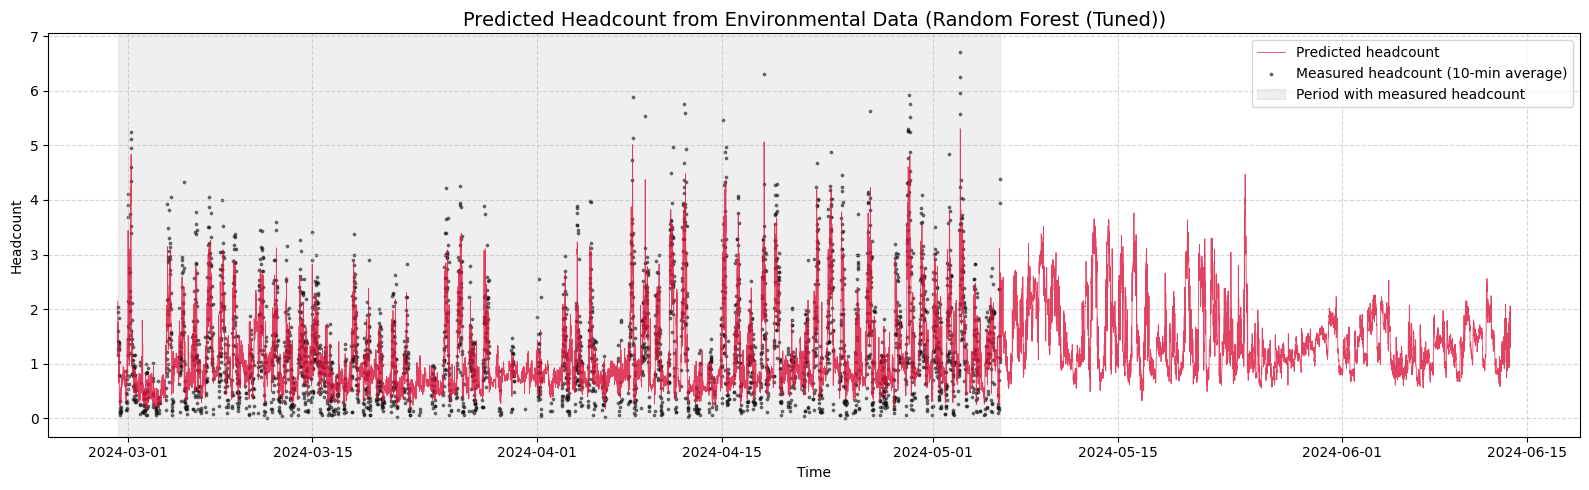

In [73]:
# 1. Predict headcount for every environmental reading
predictions_df = binned_env_df[['time'] + features].dropna(subset=features).copy()
predictions_df['predicted_headcount'] = final_model.predict(predictions_df[features]).clip(min=0)

# 2. Attach the measured headcount and train/test label where available
predictions_df = predictions_df.merge(binned_occ_df[['time', 'avg_headcount']], on='time', how='left')
predictions_df = predictions_df.rename(columns={'avg_headcount': 'measured_headcount'})
train_times = set(train_data.loc[X_train.index, 'time'])
test_times = set(train_data.loc[X_test.index, 'time'])
predictions_df['split'] = np.select(
    [predictions_df['time'].isin(train_times), predictions_df['time'].isin(test_times)],
    ['train', 'test'], default='unlabelled')

# 3. Flag readings outside the training period
train_start, train_end = train_data['time'].min(), train_data['time'].max()
predictions_df['outside_training_period'] = (predictions_df['time'] < train_start) | (predictions_df['time'] > train_end)

predictions_df.to_csv(OUTPUT_DIR / 'predicted_headcount.csv', index=False)

print(f"Predictions for {len(predictions_df):,} readings saved to outputs/predicted_headcount.csv")
display(predictions_df.groupby('split').agg(
    readings=('predicted_headcount', 'size'),
    mean_predicted=('predicted_headcount', 'mean'),
    mean_measured=('measured_headcount', 'mean'),
    outside_training_period=('outside_training_period', 'sum'),
).round(3))
display(predictions_df[predictions_df['split'] == 'unlabelled'][['time', 'predicted_headcount', 'outside_training_period']].head())

# Predicted vs measured headcount over time
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(predictions_df['time'], predictions_df['predicted_headcount'], color='crimson', linewidth=0.6, alpha=0.8, label='Predicted headcount')
ax.scatter(predictions_df['time'], predictions_df['measured_headcount'], s=3, color='black', alpha=0.5, label='Measured headcount (10-min average)')
ax.axvspan(train_start, train_end, color='grey', alpha=0.12, label='Period with measured headcount')
ax.set_title(f'Predicted Headcount from Environmental Data ({final_model_name})', fontsize=14)
ax.set_xlabel('Time')
ax.set_ylabel('Headcount')
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig(FIG_DIR / 'predicted_headcount_time_series.png', dpi=150)
plt.show()


## 2. Model Performance Metrics


In [74]:
metrics_df = comparison_df.sort_values('RMSE').reset_index(drop=True)
metrics_df.insert(0, 'Rank (by RMSE)', range(1, len(metrics_df) + 1))
metrics_df['Role'] = metrics_df['Model'].map(lambda m: 'Baseline' if m.startswith('Polynomial')
                                            else 'Final model' if m == final_model_name else 'Alternative')
metrics_df.to_csv(OUTPUT_DIR / 'model_performance_metrics.csv', index=False)

print("Test-set performance (saved to outputs/model_performance_metrics.csv):")
display(metrics_df[['Rank (by RMSE)', 'Model', 'Role', 'RMSE', 'MAE', 'R² Score']].round(4))


Test-set performance (saved to outputs/model_performance_metrics.csv):


,Rank (by RMSE),Model,Role,RMSE,MAE,R² Score
0,1,Random Forest (Tuned),Final model,0.7097,0.5364,0.5137
1,2,Random Forest,Alternative,0.7202,0.5440,0.4992
2,3,Gradient Boosting,Alternative,0.7861,0.6004,0.4033
3,4,Polynomial Regression (Deg 2),Baseline,0.8686,0.6670,0.2716


## 3. Sensitivity Analysis Results


In [75]:
sensitivity_out = sensitivity_df.copy()
sensitivity_out.insert(0, 'Variable', sensitivity_out['Dropped Feature'].map(SHORT_NAMES))
sensitivity_out = sensitivity_out.drop(columns='Dropped Feature')
sensitivity_out.to_csv(OUTPUT_DIR / 'sensitivity_analysis_results.csv', index=False)

print(f"Leave-one-feature-out results for {final_model_name} (saved to outputs/sensitivity_analysis_results.csv)")
print(f"All features: RMSE {base_rmse:.4f} | MAE {base_mae:.4f} | R² {base_r2:.4f}")
display(sensitivity_out.round(4))


Leave-one-feature-out results for Random Forest (Tuned) (saved to outputs/sensitivity_analysis_results.csv)
All features: RMSE 0.7097 | MAE 0.5364 | R² 0.5137


,Variable,New RMSE,New MAE,New R²,RMSE Increase,MAE Increase,R² Decrease
0,CO₂ (ppm),0.7860,0.5840,0.4036,0.0763,0.0476,0.1102
1,Formaldehyde (µg/m³),0.7685,0.5756,0.4299,0.0588,0.0393,0.0839
2,Pressure (hPa),0.7473,0.5677,0.4608,0.0376,0.0313,0.0529
3,Humidity (%RH),0.7449,0.5693,0.4643,0.0352,0.0330,0.0494
4,Temperature (°C),0.7352,0.5577,0.4782,0.0255,0.0214,0.0355
5,PM2.5 (µg/m³),0.7108,0.5366,0.5122,0.0011,0.0002,0.0015
6,VOC (ppb),0.7088,0.5367,0.5149,-0.0008,0.0004,-0.0012
7,PM1 (µg/m³),0.7088,0.5374,0.5150,-0.0009,0.0010,-0.0013
8,PM10 (µg/m³),0.7053,0.5321,0.5198,-0.0044,-0.0043,-0.0060
9,PM4 (µg/m³),0.7040,0.5304,0.5215,-0.0057,-0.0059,-0.0078


## 4. Feature Importance Ranking

Each variable is ranked by three independent measures, and the overall rank is the average of the three:

* **Sensitivity:** increase in the final model's test RMSE when the variable is removed (the primary measure).
* **Model importance:** the final model's built-in importance (how much each variable reduces error across all tree splits).
* **Correlation:** absolute Pearson correlation with headcount in the training data.


In [76]:
ranking_df = pd.DataFrame({'Feature': features})
ranking_df['Variable'] = ranking_df['Feature'].map(SHORT_NAMES)
ranking_df['RMSE increase when removed'] = ranking_df['Feature'].map(sensitivity_df.set_index('Dropped Feature')['RMSE Increase'])
ranking_df['Model importance'] = final_model.feature_importances_ if hasattr(final_model, 'feature_importances_') else np.nan
ranking_df['|Correlation| with headcount'] = X_train.corrwith(y_train).abs().values

ranking_df['Sensitivity rank'] = ranking_df['RMSE increase when removed'].rank(ascending=False).astype(int)
ranking_df['Importance rank'] = ranking_df['Model importance'].rank(ascending=False).astype(int)
ranking_df['Correlation rank'] = ranking_df['|Correlation| with headcount'].rank(ascending=False).astype(int)
ranking_df['Average rank'] = ranking_df[['Sensitivity rank', 'Importance rank', 'Correlation rank']].mean(axis=1)
ranking_df = ranking_df.sort_values(['Average rank', 'Sensitivity rank']).reset_index(drop=True)
ranking_df.insert(0, 'Overall rank', range(1, len(ranking_df) + 1))
ranking_df = ranking_df.drop(columns='Feature')
ranking_df.to_csv(OUTPUT_DIR / 'feature_importance_ranking.csv', index=False)

print("Feature importance ranking (saved to outputs/feature_importance_ranking.csv):")
display(ranking_df.round(4))
print(f"\nStrongest predictor of occupancy: {ranking_df.loc[0, 'Variable']}")
print("Light level: not measured by the sensor, so it cannot be ranked.")


Feature importance ranking (saved to outputs/feature_importance_ranking.csv):


,Overall rank,Variable,RMSE increase when removed,Model importance,|Correlation| with headcount,Sensitivity rank,Importance rank,Correlation rank,Average rank
0,1,CO₂ (ppm),0.0763,0.3470,0.4745,1,1,1,1.0000
1,2,Formaldehyde (µg/m³),0.0588,0.1201,0.1644,2,4,2,2.6667
2,3,Humidity (%RH),0.0352,0.1236,0.1210,4,2,5,3.6667
3,4,Temperature (°C),0.0255,0.1046,0.1356,5,5,3,4.3333
4,5,Pressure (hPa),0.0376,0.1207,0.0246,3,3,10,5.3333
5,6,VOC (ppb),-0.0008,0.0375,0.1296,7,8,4,6.3333
6,7,PM2.5 (µg/m³),0.0011,0.0335,0.0409,6,9,7,7.3333
7,8,PM1 (µg/m³),-0.0009,0.0310,0.0562,8,10,6,8.0000
8,9,PM10 (µg/m³),-0.0044,0.0429,0.0287,9,6,9,8.0000
9,10,PM4 (µg/m³),-0.0057,0.0391,0.0340,10,7,8,8.3333



Strongest predictor of occupancy: CO₂ (ppm)
Light level: not measured by the sensor, so it cannot be ranked.


## 5. Visualisations

The four required figures are recreated here in one place and saved to `outputs/figures/`.


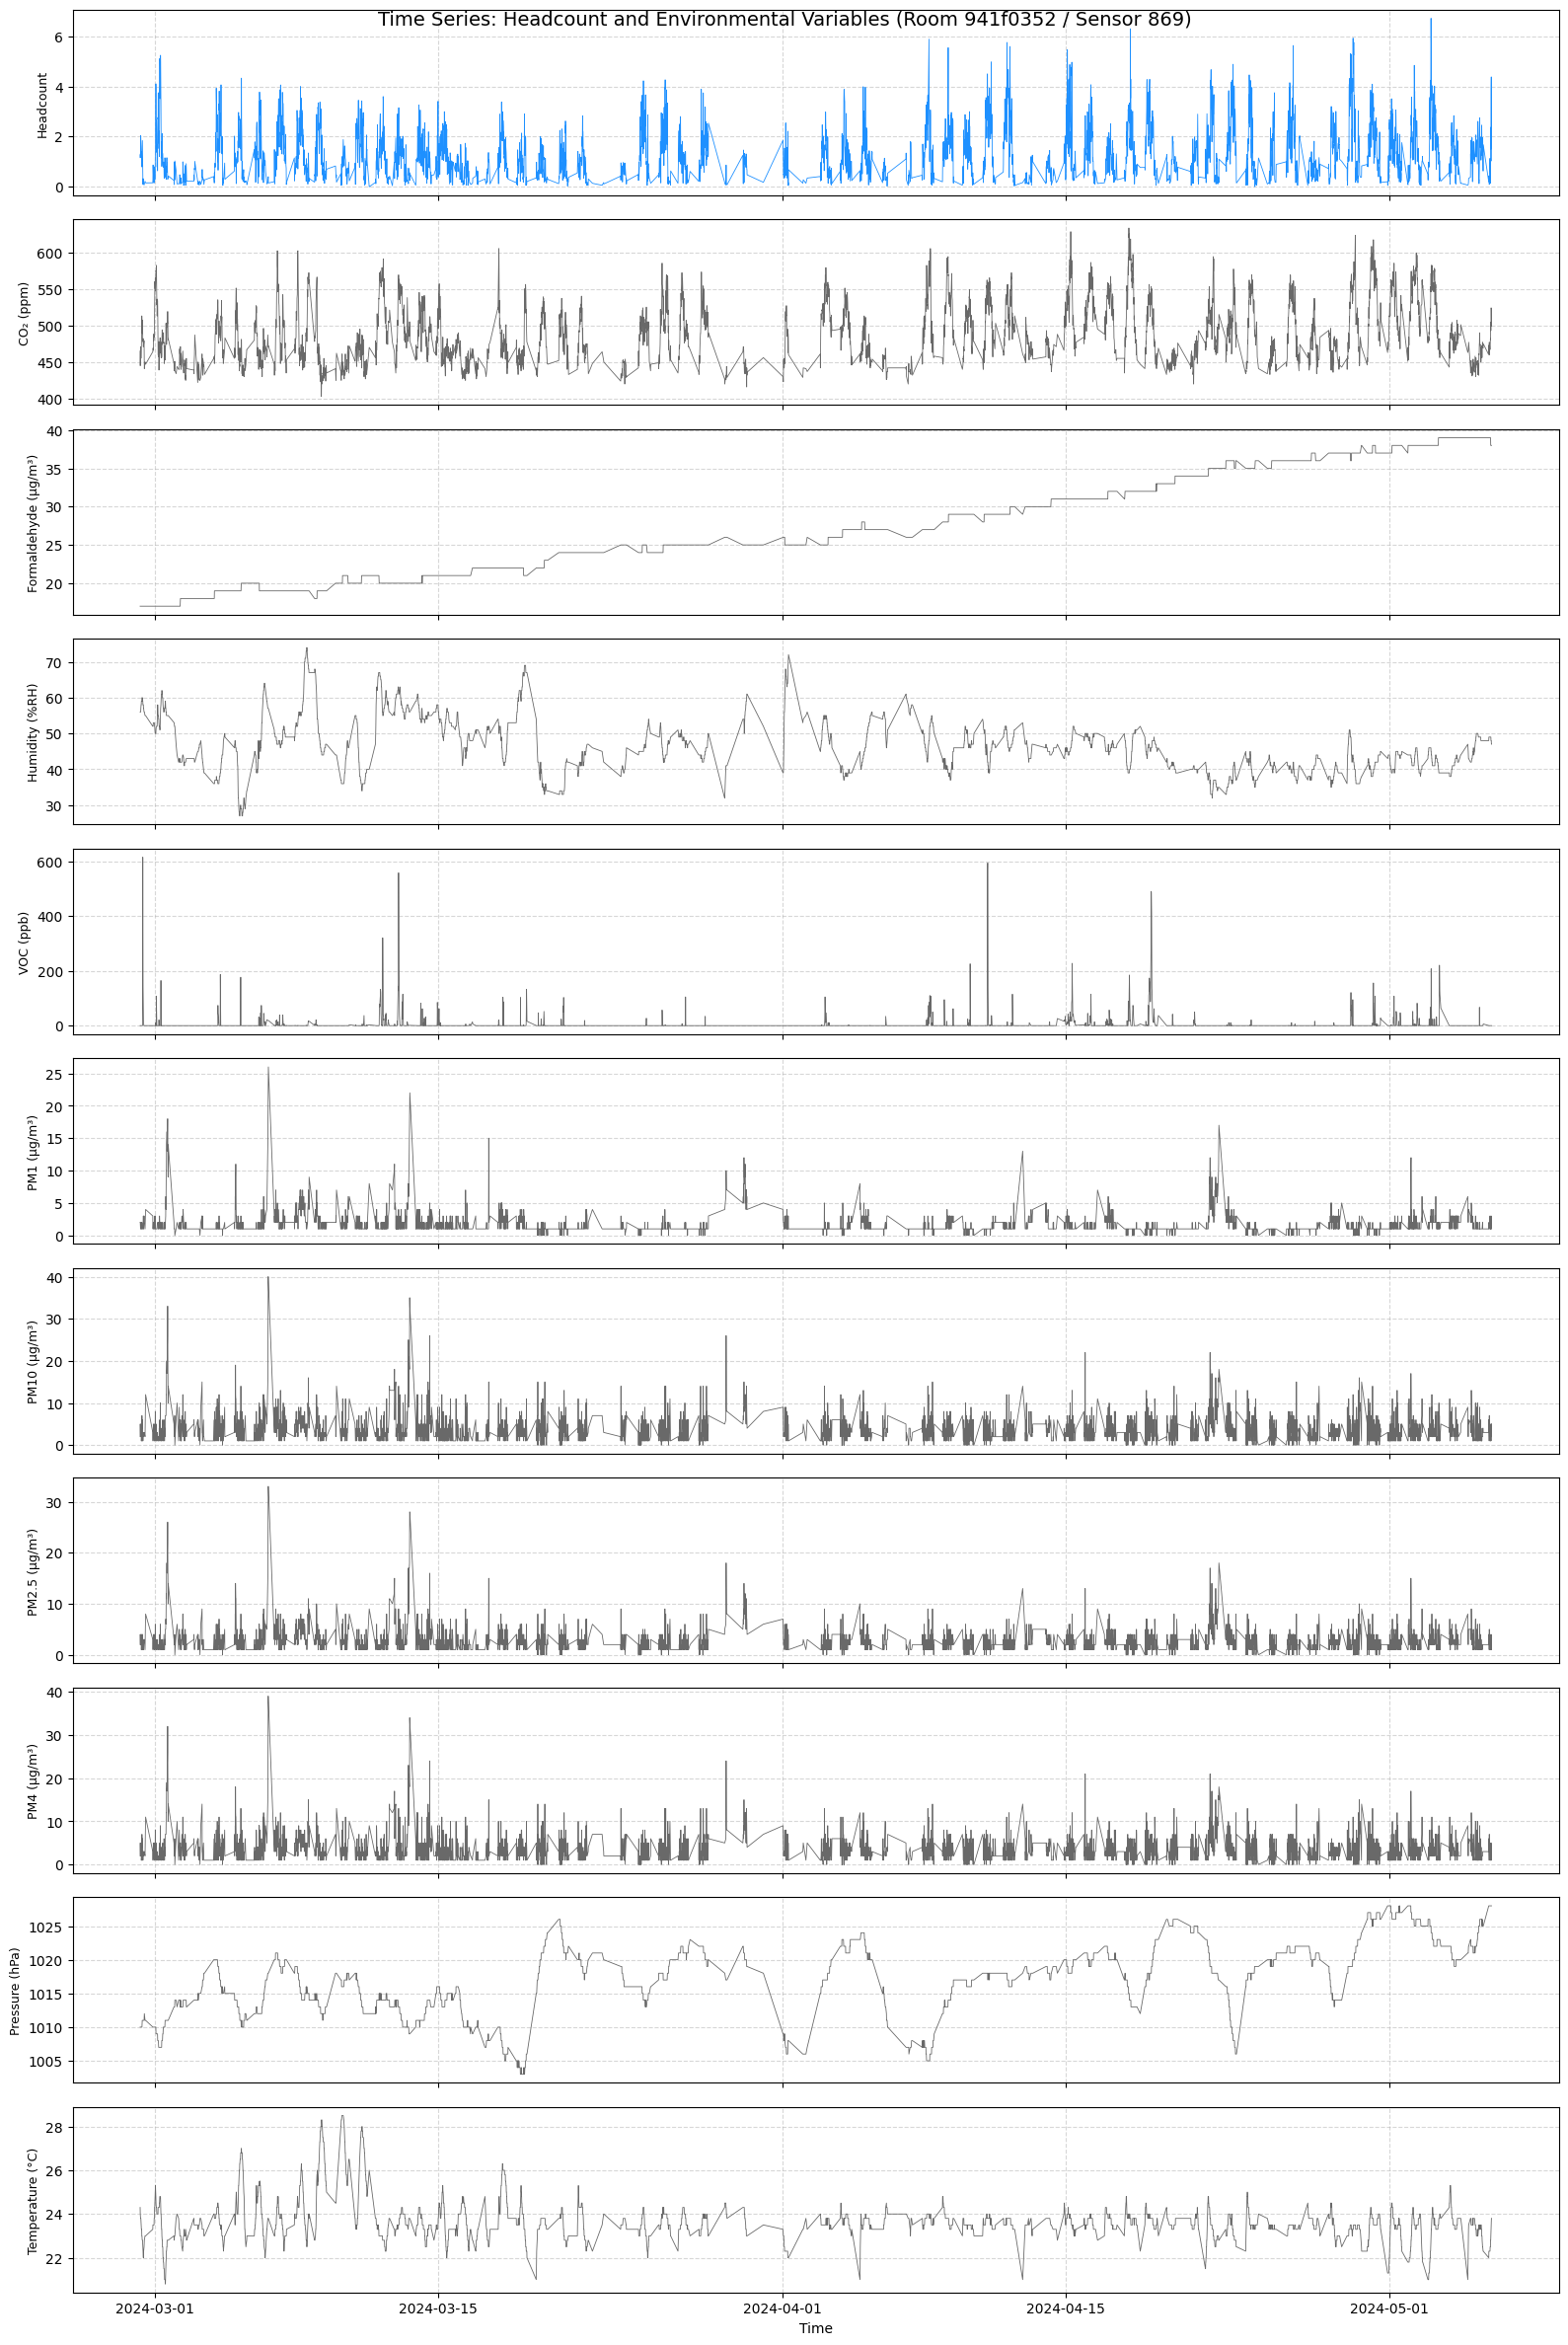

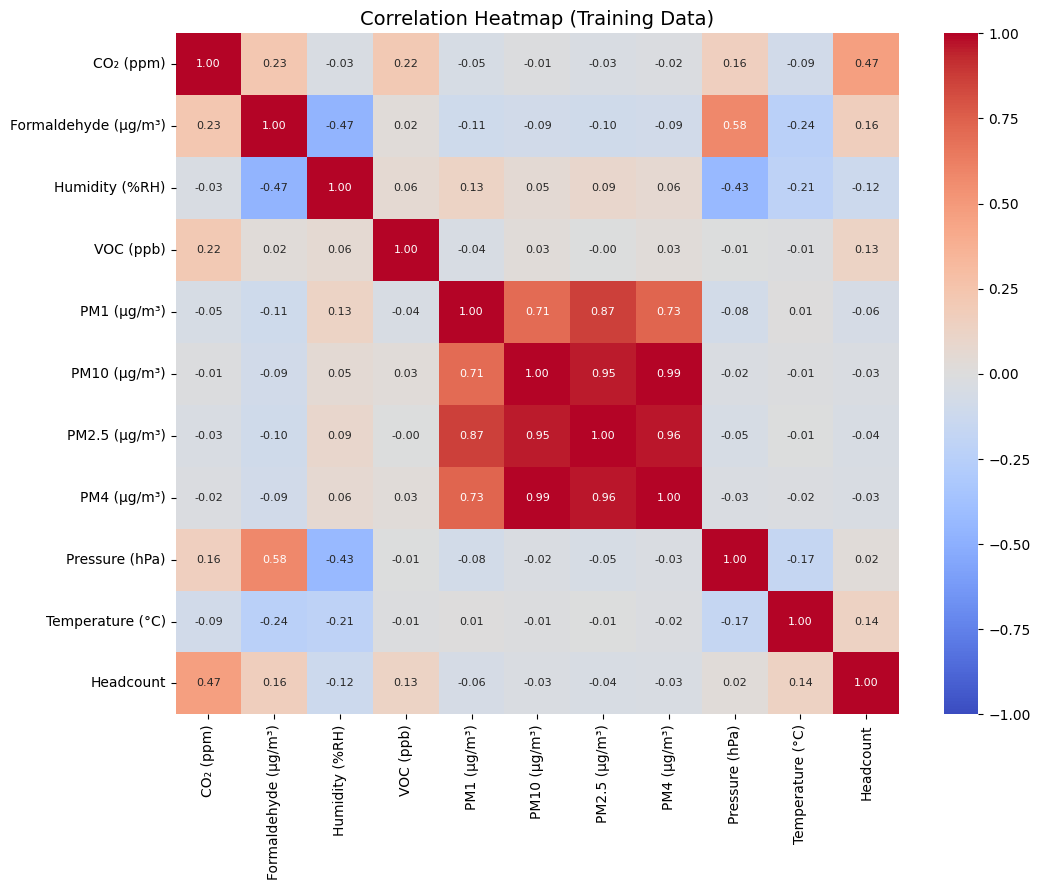

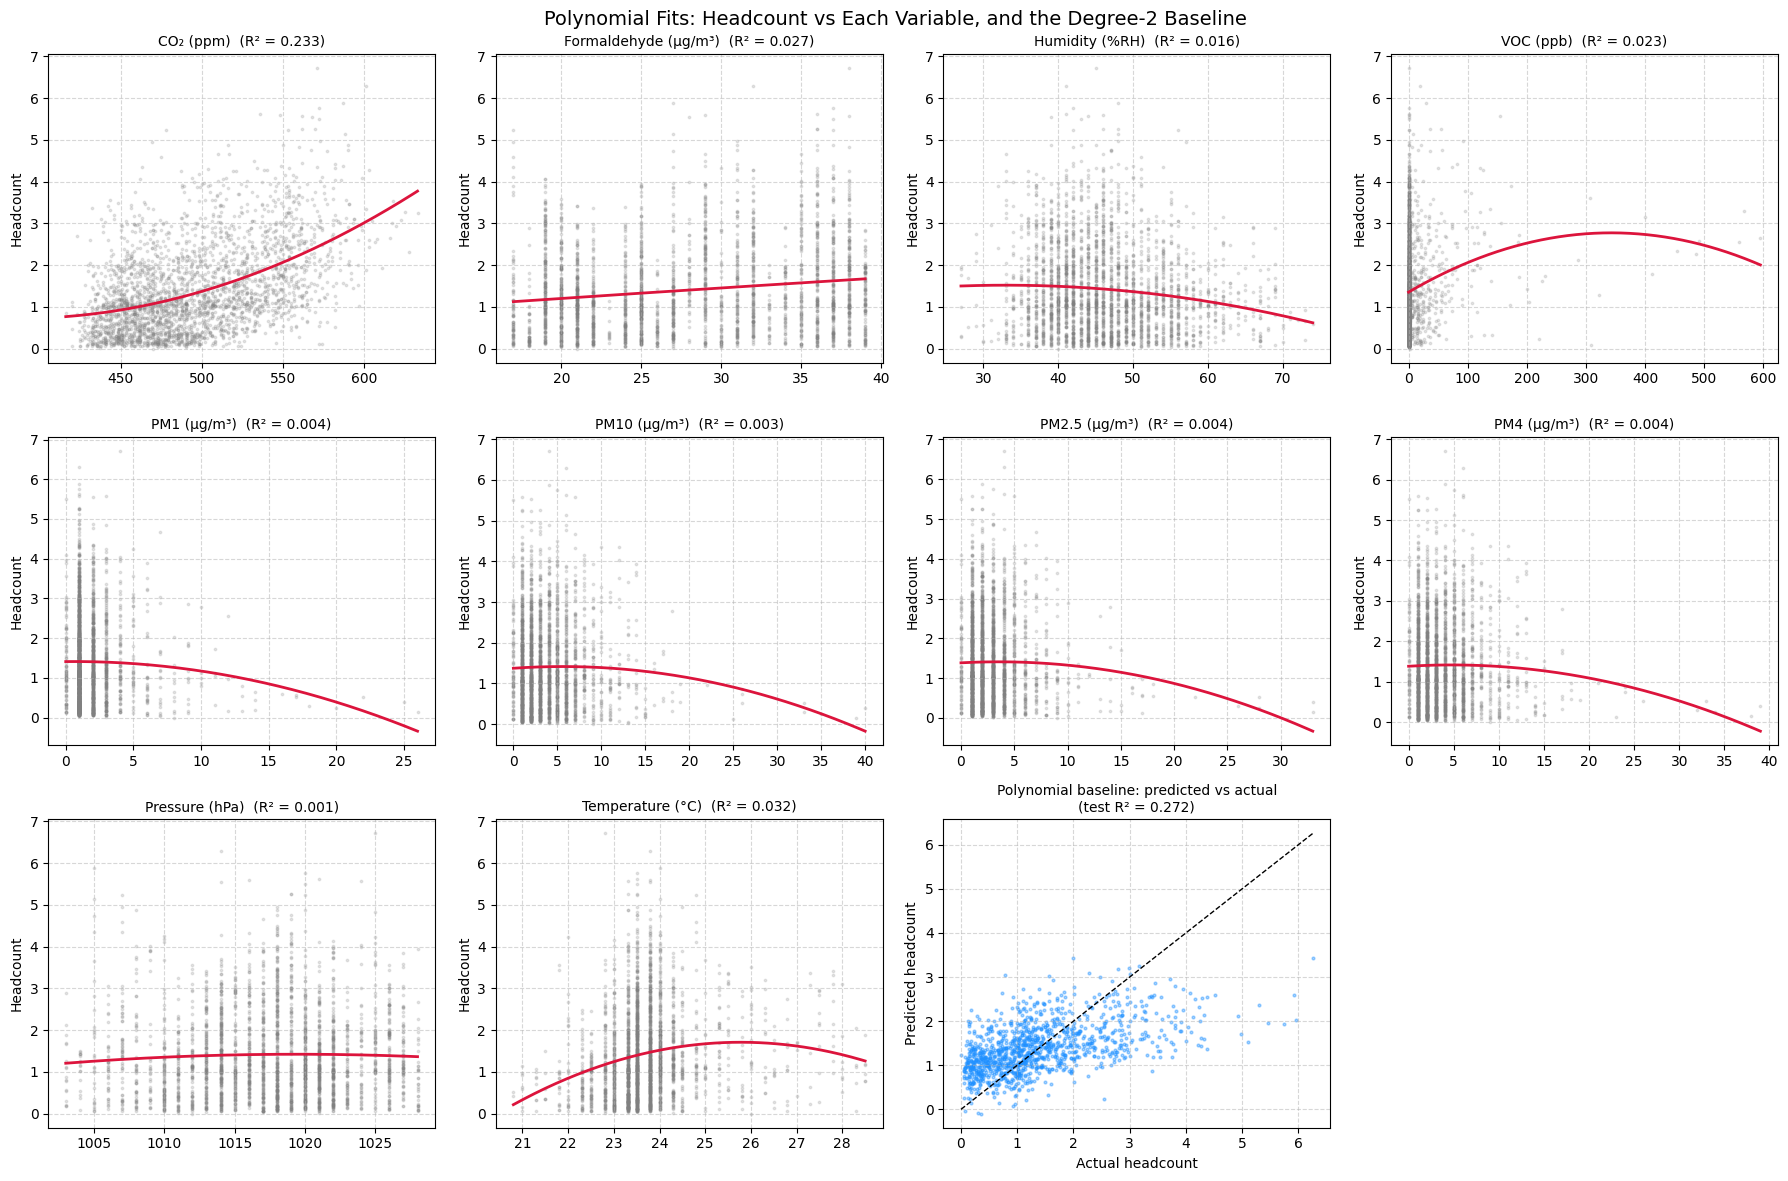

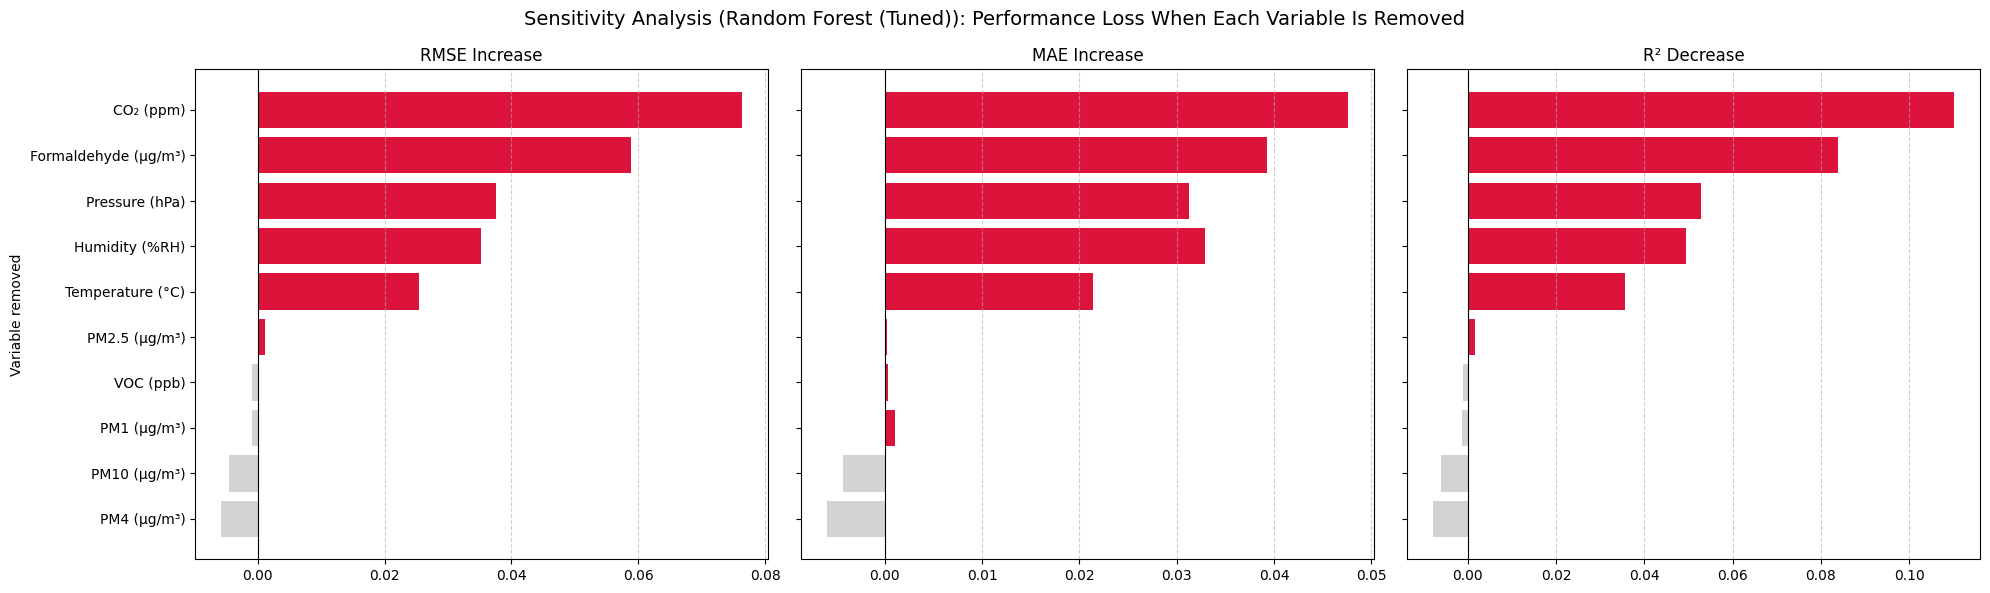

Saved figures:
 - outputs/figures/correlation_heatmap.png
 - outputs/figures/polynomial_fit.png
 - outputs/figures/predicted_headcount_time_series.png
 - outputs/figures/sensitivity_analysis.png
 - outputs/figures/time_series.png


In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

# (a) Time series: headcount and every environmental variable over the modelling period
ts_cols = ['avg_headcount'] + features
fig, axes = plt.subplots(len(ts_cols), 1, figsize=(16, 2.2 * len(ts_cols)), sharex=True)
for ax, col in zip(axes, ts_cols):
    ax.plot(train_data['time'], train_data[col], linewidth=0.6,
            color='dodgerblue' if col == 'avg_headcount' else 'dimgray')
    ax.set_ylabel('Headcount' if col == 'avg_headcount' else SHORT_NAMES[col], fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[-1].set_xlabel('Time')
fig.suptitle('Time Series: Headcount and Environmental Variables (Room 941f0352 / Sensor 869)', fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / 'time_series.png', dpi=150)
plt.show()

# (b) Correlation heatmap (training data)
corr = train_eda_df.rename(columns={**SHORT_NAMES, 'avg_headcount': 'Headcount'}).corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation Heatmap (Training Data)', fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / 'correlation_heatmap.png', dpi=150)
plt.show()

# (c) Polynomial fit: single-variable quadratic fits plus the baseline's predicted vs actual
n_cols = 4
n_rows = int(np.ceil((len(features) + 1) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.ravel()
for ax, feature in zip(axes, features):
    xv, yv = X_train[feature].to_numpy(), y_train.to_numpy()
    coeffs = np.polyfit(xv, yv, deg=2)
    r2_single = 1 - np.sum((yv - np.polyval(coeffs, xv)) ** 2) / np.sum((yv - yv.mean()) ** 2)
    x_line = np.linspace(xv.min(), xv.max(), 200)
    ax.scatter(xv, yv, s=3, alpha=0.2, color='grey')
    ax.plot(x_line, np.polyval(coeffs, x_line), color='crimson', linewidth=2)
    ax.set_title(f'{SHORT_NAMES[feature]}  (R² = {r2_single:.3f})', fontsize=10)
    ax.set_ylabel('Headcount')
    ax.grid(True, linestyle='--', alpha=0.5)
ax = axes[len(features)]
ax.scatter(y_test, y_pred, s=4, alpha=0.4, color='dodgerblue')
lim = max(y_test.max(), y_pred.max())
ax.plot([0, lim], [0, lim], 'k--', linewidth=1)
ax.set_title(f'Polynomial baseline: predicted vs actual\n(test R² = {r2:.3f})', fontsize=10)
ax.set_xlabel('Actual headcount')
ax.set_ylabel('Predicted headcount')
ax.grid(True, linestyle='--', alpha=0.5)
for ax in axes[len(features) + 1:]:
    ax.set_visible(False)
fig.suptitle('Polynomial Fits: Headcount vs Each Variable, and the Degree-2 Baseline', fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / 'polynomial_fit.png', dpi=150)
plt.show()

# (d) Sensitivity plots
plot_df = sensitivity_out.sort_values('RMSE Increase', ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, metric in zip(axes, ['RMSE Increase', 'MAE Increase', 'R² Decrease']):
    colours = ['crimson' if v > 0 else 'lightgrey' for v in plot_df[metric]]
    ax.barh(plot_df['Variable'], plot_df[metric], color=colours)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(metric, fontsize=12)
    ax.grid(axis='x', linestyle='--', alpha=0.6)
axes[0].invert_yaxis()
axes[0].set_ylabel('Variable removed')
fig.suptitle(f'Sensitivity Analysis ({final_model_name}): Performance Loss When Each Variable Is Removed', fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / 'sensitivity_analysis.png', dpi=150)
plt.show()

print("Saved figures:")
for f in sorted(FIG_DIR.glob('*.png')):
    print(' -', f.as_posix())


## Resources

**Datasets Used:**
*   **Occupancy Dataset:** `DATA/5occupancySensor_MayToDec2024_9MRows.csv` (room 941f0352 only: raw headcount events, 289,206 rows).
*   **Environmental Dataset:** `DATA/5EnvSensor_MayToDec2024_180kRows.csv` (sensor 6012002000869 only: CO₂, temperature, humidity, pressure, formaldehyde, light VOCs and particulate matter 1/2.5/4/10, flattened from JSON using each reading's measurement timestamp).
*   **Sensor Mapping Registry:** `DATA/Sensor ID and Locations.xlsx` (locates sensor 869 in room G.38).

**Key Data Overlap & Modelling Figures:**
*   **Overlap window:** 29 February 2024 – 6 May 2024.
*   **Modelling dataset:** **4,009** environmental readings paired with a 10-minute time-weighted average headcount.
    *   **Training set (70%):** 2,806 readings.
    *   **Test/validation set (30%):** 1,203 readings.
*   **Best model:** tuned Random Forest (300 trees, max_depth 20, max_features 0.5): RMSE 0.710, MAE 0.538, R² 0.513, against the polynomial baseline (RMSE 0.869, MAE 0.667, R² 0.272).
*   **Predictions:** headcount estimated for all 13,800 sensor readings, saved in `outputs/predicted_headcount.csv` (9,791 of them have no measured headcount; 5,193 fall after the training period and are flagged).
*   **Key finding:** carbon dioxide is the strongest environmental predictor of room headcount.
